In [1]:
"""
~ 3 - 4 hours expected.
"""
import warnings
warnings.filterwarnings("ignore")
import os, time
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, least_squares, OptimizeWarning
from scipy.stats import truncnorm
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
warnings.filterwarnings("ignore", category=OptimizeWarning)

t_start = time.time()
ROOT = Path("/Users/wangtao/Downloads/files-6")
PREPROCESSED = ROOT / "Preprocessed_Data.xlsx"
TRANSFORMED = ROOT / "Transformed_Data.xlsx"
RAW_DATA = ROOT / "Charpy_Impact_Test_Dataset.xlsx"

TCOL, ECOL = "Test Temperature (C)", "Impact energy (J)"
TARGET_T, TARGET_E = "Transformed Temperature (°C)", "Transformed Absorbed Energy (J)"
CURVE_COL, REF_COL = "DBTT Fitted Curve", "Reference"
VALID_REFERENCES = [52, 53, 59]

SUB_TO_FULL_CURVE_MAP = {
    218: 216, 220: 216, 219: 217, 221: 217,
    226: 222, 230: 222, 234: 222, 242: 222,
    227: 223, 231: 223, 235: 223, 243: 223,
    228: 224, 232: 224, 236: 224, 244: 224,
    229: 225, 233: 225, 237: 225, 245: 225,
    270: 267, 272: 267, 273: 268, 294: 268,
    269: 266, 271: 266,
}
FULL_SIZE_GEOMETRY = {
    "Length (mm)": 55.0, "Width (mm)": 10.0, "Thickness (mm)": 10.0,
    "Notch Depth (mm)": 2.0, "Notch Angle (deg)": 45.0, "Notch Root Radius (mm)": 0.25,
}
FEATURE_COLS = [
    "C, wt.%", "Si, wt.%", "Mn, wt.%", "P, wt.%", "S, wt.%", "Ni, wt.%",
    "Cr, wt.%", "Mo, wt.%", "Fe, wt.%", "Cu, wt.%", "V, wt.%",
    "Manufacturer", "Treatment", "Post Treatment Temperature (ºC)",
    "Post Treatment Time (h)", "Cooling", "Microstructure", "Grain size (um)",
    "Irradiated Specimen", "Irradiation Dose (n/cm^2)", "Irradiation Temperature (ºC)",
    "Length (mm)", "Width (mm)", "Thickness (mm)", "Notch Depth (mm)",
    "Notch Angle (deg)", "Notch Root Radius (mm)", "Notch Shape",
    "Test Standard", TCOL, "Orientation", "Test Condition Statement",
]
GEOMETRY_COLS = ["Length (mm)", "Width (mm)", "Thickness (mm)",
                  "Notch Depth (mm)", "Notch Angle (deg)", "Notch Root Radius (mm)"]
CV_FOLDS = {
    "fold_1": [218.0, 226.0, 233.0, 269.0, 272.0],
    "fold_2": [220.0, 227.0, 234.0, 231.0, 270.0],
    "fold_3": [219.0, 228.0, 232.0, 237.0, 294.0],
    "fold_4": [221.0, 229.0, 236.0, 230.0, 245.0],
    "fold_5": [242.0, 235.0, 244.0, 273.0, 271.0, 243.0],
}


def load_merged_subsize_data():
    df_all = pd.read_excel(PREPROCESSED, header=0)
    df_transformed = pd.read_excel(TRANSFORMED, header=0)
    key = [REF_COL, CURVE_COL, TCOL]
    left = df_all.copy()
    right = df_transformed[key + [TARGET_T, TARGET_E]].copy()
    for c in [REF_COL, CURVE_COL]:
        left[c] = pd.to_numeric(left[c], errors="coerce")
        right[c] = pd.to_numeric(right[c], errors="coerce")
    left[TCOL] = pd.to_numeric(left[TCOL], errors="coerce")
    right[TCOL] = pd.to_numeric(right[TCOL], errors="coerce")
    right = right.sort_values(key).drop_duplicates(subset=key, keep="first")
    df = left.merge(right, on=key, how="left", validate="many_to_one")
    assert len(df) == len(df_all)
    df = df.astype("float64")
    return df[df[REF_COL].isin(VALID_REFERENCES)].reset_index(drop=True)


def load_raw_fullsize_data():
    full_df = pd.read_excel(RAW_DATA, header=1)
    full_df.columns = full_df.columns.str.strip()
    full_df = full_df[full_df[REF_COL].isin(VALID_REFERENCES)]
    full_df = full_df[full_df["Width (mm)"] == 10].copy()
    full_df[TCOL] = pd.to_numeric(full_df[TCOL], errors="coerce")
    full_df[ECOL] = pd.to_numeric(full_df[ECOL], errors="coerce")
    return full_df.reset_index(drop=True)


def tanh3(temp, use, dbtt, k):
    return 0.5 * use * (1.0 + np.tanh((temp - dbtt) / k))


def fit_tanh3_curve(temp, energy, min_points=4):
    temp = pd.to_numeric(pd.Series(temp), errors="coerce").to_numpy(float)
    energy = pd.to_numeric(pd.Series(energy), errors="coerce").to_numpy(float)
    mask = np.isfinite(temp) & np.isfinite(energy)
    temp, energy = temp[mask], energy[mask]
    if len(temp) < min_points or np.nanmax(temp) - np.nanmin(temp) < 5:
        return None, None
    order = np.argsort(temp)
    temp, energy = temp[order], energy[order]
    use0 = max(float(np.nanmax(energy)), 1.0)
    dbtt0 = float(temp[np.nanargmin(np.abs(energy - np.nanmedian(energy)))])
    k0 = max(float((np.nanmax(temp) - np.nanmin(temp)) / 6.0), 5.0)
    try:
        params, _ = curve_fit(tanh3, temp, energy, p0=[use0, dbtt0, k0],
                               bounds=([0.2, np.nanmin(temp) - 300.0, 1.0],
                                       [max(3.0 * use0, 10.0), np.nanmax(temp) + 300.0, 500.0]),
                               maxfev=30000)
        return params, energy - tanh3(temp, *params)
    except Exception:
        return None, None


def tanh_fn(x, a, b, c, d):
    return a * np.tanh(b * (x - c)) + d


def fit_tanh_bounded(x, y):
    df_xy = pd.DataFrame({"x": x, "y": y}).groupby("x", as_index=False)["y"].mean()
    x = df_xy["x"].to_numpy(float); y = df_xy["y"].to_numpy(float)
    if len(x) < 4 or np.nanstd(y) < 1e-6:
        raise RuntimeError("not enough variation")
    scaler = StandardScaler()
    xs = scaler.fit_transform(x.reshape(-1, 1)).ravel()
    y_min, y_max = float(y.min()), float(y.max())
    y_span = max(y_max - y_min, 1.0)
    lb = np.array([0.0, 1e-3, xs.min() - 0.5, y_min - 0.5 * y_span])
    ub = np.array([max(2.0 * y_span, 20.0), 10.0, xs.max() + 0.5, y_max + 0.5 * y_span])
    p0 = np.array([0.5 * y_span, 1.0, float(np.median(xs)), float(np.mean(y))])

    def resid(p):
        return tanh_fn(xs, *p) - y

    res = least_squares(resid, p0, bounds=(lb, ub), loss="soft_l1", f_scale=1.0, max_nfev=20000)
    if not res.success:
        raise RuntimeError("fit did not converge")
    return res.x, scaler


def dbtt_use_from_params(params, scaler):
    a, b, c, d = params
    use = a + d
    dbtt = scaler.inverse_transform([[c]])[0, 0]
    return float(use), float(dbtt)


def yugandhar_transform(temp_sub, energy_sub, sub_params, full_params):
    use_sub, dbtt_sub, _k_sub = sub_params
    use_full, dbtt_full, k_full = full_params
    temp_sub = np.asarray(temp_sub, dtype=float)
    energy_sub = np.asarray(energy_sub, dtype=float)
    shift = dbtt_full - dbtt_sub
    temp_transformed = temp_sub + shift
    residual = energy_sub - tanh3(temp_sub, *sub_params)
    scaled_residual = residual * (use_full / max(use_sub, 1e-6))
    energy_transformed = tanh3(temp_transformed, *full_params) + scaled_residual
    return temp_transformed, energy_transformed


def fit_full_curve_params(full_raw_df, full_curve_id):
    sub = full_raw_df[full_raw_df[CURVE_COL] == full_curve_id]
    return fit_tanh3_curve(sub[TCOL], sub[ECOL])


df = load_merged_subsize_data()
full_raw = load_raw_fullsize_data()
print("Loaded sub-sized and full-sized curves successfully.")




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

Loaded sub-sized and full-sized curves successfully.


In [2]:
# ============================================================ Step 1: Gaussian-Local + Envelope Sampling -- Uncertainty-aware dual sampling
FLOOR = 1e-6
N_SYNTHETIC = 200
GL_RNG_SEED = 20260826
ENVELOPE_RNG_SEED = 20262826
GRID = 600


def _kernel_w(a, b, h):
    d = (a[:, None] - b[None, :]) / h
    return np.exp(-0.5 * d ** 2)


def sigma_at(tq, t_obs, resid, h):
    tq = np.atleast_1d(tq)
    w = _kernel_w(tq, t_obs, h)
    num = (w * resid[None, :] ** 2).sum(1)
    den = np.maximum(w.sum(1), FLOOR)
    return np.sqrt(num / den)


def mean_at(tq, t_obs, resid, h):
    tq = np.atleast_1d(tq)
    w = _kernel_w(tq, t_obs, h)
    return (w * resid[None, :]).sum(1) / np.maximum(w.sum(1), FLOOR)


def _loo_log_lik(h, t_obs, resid):
    n = len(t_obs); total = 0.0; idx = np.arange(n)
    for i in range(n):
        mask = idx != i
        s = sigma_at(t_obs[i:i + 1], t_obs[mask], resid[mask], h)[0]
        s = max(s, FLOOR)
        total += -0.5 * np.log(2 * np.pi * s ** 2) - resid[i] ** 2 / (2 * s ** 2)
    return total


def select_bandwidth(t_obs, resid, n_grid=50):
    t_sorted = np.sort(np.unique(t_obs))
    gaps = np.diff(t_sorted); gaps = gaps[gaps > 1e-9]
    hi = t_obs.max() - t_obs.min()
    lo = gaps.min() if len(gaps) else hi
    lo = min(lo, 0.5 * hi) if hi > 0 else 1.0
    grid = np.geomspace(max(lo, 1e-6), max(hi, lo * 2), n_grid)
    scores = [_loo_log_lik(h, t_obs, resid) for h in grid]
    return float(grid[int(np.argmax(scores))])


# --- Gaussian-Local sampling ---
def positions_rule_sigma(t_obs, resid, n, rng, h, grid=GRID):
    tg = np.linspace(t_obs.min(), t_obs.max(), grid)
    w = sigma_at(tg, t_obs, resid, h)
    w = np.maximum(w, FLOOR)
    idx = rng.choice(grid, size=n, p=w / w.sum())
    step = tg[1] - tg[0]
    return np.clip(tg[idx] + rng.uniform(-step / 2, step / 2, n), t_obs.min(), t_obs.max())


def gaussian_local_sample(t_obs, resid, params, n, rng, h):
    T = positions_rule_sigma(t_obs, resid, n, rng, h)
    mu = tanh3(T, *params) + mean_at(T, t_obs, resid, h)
    sig = np.maximum(sigma_at(T, t_obs, resid, h), FLOOR)
    E = rng.normal(mu, sig)
    return T, E


# --- Envelope Sampling ---
def envelope(tg, t_obs, resid, h):
    tg = np.atleast_1d(tg)
    w = _kernel_w(tg, t_obs, h)
    pos = np.where(resid > 0, resid, 0.0)
    neg = np.where(resid < 0, resid, 0.0)
    up = (w * pos[None, :]).max(1)
    lo = (w * neg[None, :]).min(1)
    return lo, up


def positions_rule_c(t_obs, resid, n, rng, h, grid=GRID):
    tg = np.linspace(t_obs.min(), t_obs.max(), grid)
    lo, up = envelope(tg, t_obs, resid, h)
    w = np.maximum(up - lo, 0.0)
    if w.sum() <= 0:
        w = np.ones_like(tg)
    idx = rng.choice(grid, size=n, p=w / w.sum())
    step = tg[1] - tg[0]
    return np.clip(tg[idx] + rng.uniform(-step / 2, step / 2, n), t_obs.min(), t_obs.max())


def envelope_sample(t_obs, resid, params, n, rng, h):
    T = positions_rule_c(t_obs, resid, n, rng, h)
    lo, up = envelope(T, t_obs, resid, h)
    E = tanh3(T, *params) + lo + rng.random(n) * (up - lo)
    return T, E


gl_rows, envelope_rows, diag_rows = [], [], []
curve_fit_info = {}
for i, cid in enumerate(sorted(df[CURVE_COL].unique())):
    g = df[df[CURVE_COL] == cid].reset_index(drop=True)
    fit_params, _ = fit_tanh3_curve(g[TCOL], g[ECOL])
    if fit_params is None:
        continue
    t_obs = pd.to_numeric(g[TCOL], errors="coerce").to_numpy(float)
    e_obs = pd.to_numeric(g[ECOL], errors="coerce").to_numpy(float)
    mask = np.isfinite(t_obs) & np.isfinite(e_obs)
    t_obs, e_obs = t_obs[mask], e_obs[mask]
    order = np.argsort(t_obs)
    t_obs, e_obs = t_obs[order], e_obs[order]
    resid = e_obs - tanh3(t_obs, *fit_params)
    h = select_bandwidth(t_obs, resid)
    curve_fit_info[int(cid)] = dict(params=fit_params, t_obs=t_obs, resid=resid, h=h)

    rng_gl = np.random.default_rng(GL_RNG_SEED + 100 * i)
    T_gl, E_gl = gaussian_local_sample(t_obs, resid, fit_params, N_SYNTHETIC, rng_gl, h)

    rng_envelope = np.random.default_rng(ENVELOPE_RNG_SEED + 100 * i)
    T_envelope, E_envelope = envelope_sample(t_obs, resid, fit_params, N_SYNTHETIC, rng_envelope, h)

    neg_gl = int((E_gl < 0).sum()); neg_envelope = int((E_envelope < 0).sum())
    diag_rows.append(dict(curve=int(cid), n_points=len(t_obs), h=h, negatives_gl=neg_gl, negatives_envelope=neg_envelope))

    base_row = g.iloc[0].copy()
    rows_gl = pd.concat([base_row.to_frame().T] * N_SYNTHETIC, ignore_index=True)
    rows_gl[TCOL] = T_gl; rows_gl[ECOL] = E_gl; rows_gl["Synthetic"] = True; rows_gl["Sample_Method"] = "GaussianLocal"
    rows_gl["Sub_USE_fit"] = fit_params[0]; rows_gl["Sub_DBTT_fit"] = fit_params[1]; rows_gl["Sub_k_fit"] = fit_params[2]
    gl_rows.append(rows_gl)

    rows_envelope = pd.concat([base_row.to_frame().T] * N_SYNTHETIC, ignore_index=True)
    rows_envelope[TCOL] = T_envelope; rows_envelope[ECOL] = E_envelope; rows_envelope["Synthetic"] = True; rows_envelope["Sample_Method"] = "Envelope"
    rows_envelope["Sub_USE_fit"] = fit_params[0]; rows_envelope["Sub_DBTT_fit"] = fit_params[1]; rows_envelope["Sub_k_fit"] = fit_params[2]
    envelope_rows.append(rows_envelope)

synthetic_gl = pd.concat(gl_rows, ignore_index=True)
synthetic_envelope = pd.concat(envelope_rows, ignore_index=True)
synthetic = pd.concat([synthetic_gl, synthetic_envelope], ignore_index=True)

diag = pd.DataFrame(diag_rows)
diag.to_csv(ROOT / "GLplusEnvelope_sampling_diagnostics.csv", index=False)
print(f"Step 1 (double sampling: Gaussian-Local + Envelope Sampling, {N_SYNTHETIC}/curve each): "
      f"synthetic points generated successfully.  [{time.time()-t_start:.0f}s]")


Step 1 (double sampling: Gaussian-Local + Envelope Sampling, 200/curve each): synthetic points generated successfully.  [1s]


## Fig. 3

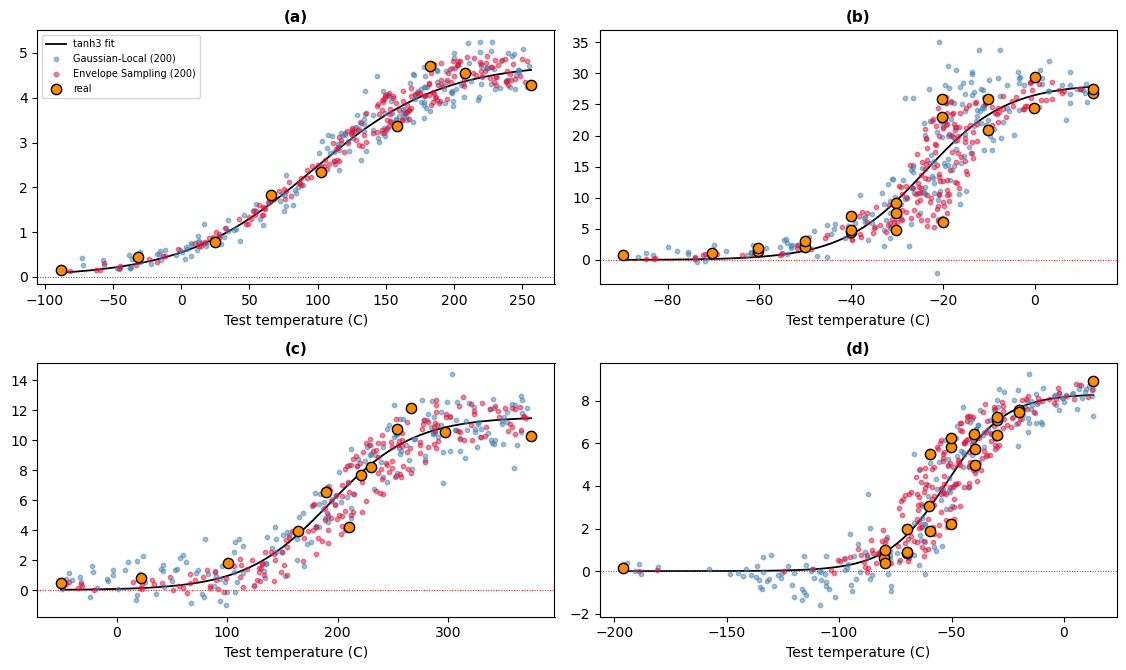

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import string

_CHECK_CURVES = [218, 226, 221, 232]
n = len(_CHECK_CURVES)
ncols = 2
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(11.5, 3.4 * nrows))
axes = axes.ravel()

for idx, cid in enumerate(_CHECK_CURVES):
    info = curve_fit_info[cid]
    params, t_obs, resid, h = info["params"], info["t_obs"], info["resid"], info["h"]
    e_obs = tanh3(t_obs, *params) + resid

    g_gl = synthetic_gl[synthetic_gl[CURVE_COL] == cid]
    g_envelope = synthetic_envelope[synthetic_envelope[CURVE_COL] == cid]

    tg = np.linspace(t_obs.min(), t_obs.max(), GRID)
    curve_y = tanh3(tg, *params)

    ax = axes[idx]
    ax.plot(tg, curve_y, color="black", lw=1.3, label="tanh3 fit")
    ax.scatter(g_gl[TCOL], g_gl[ECOL], s=10, color="steelblue", alpha=0.5, zorder=4, label=f"Gaussian-Local ({N_SYNTHETIC})")
    ax.scatter(g_envelope[TCOL], g_envelope[ECOL], s=10, color="crimson", alpha=0.5, zorder=4, label=f"Envelope Sampling ({N_SYNTHETIC})")
    ax.scatter(t_obs, e_obs, s=55, color="darkorange", edgecolor="black", zorder=5, label="real")
    ax.axhline(0, color="red", ls=":", lw=0.7)


    letter = string.ascii_lowercase[idx]
    ax.set_title(f"({letter})", fontsize=11, fontweight="bold", color="black")
    ax.set_xlabel("Test temperature (C)")
    if idx == 0:
        ax.legend(loc="upper left", fontsize=7)

for j in range(n, nrows * ncols):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig(ROOT / "Fig1_sampling_218_226_221_232.png", dpi=150, bbox_inches="tight")
plt.show()


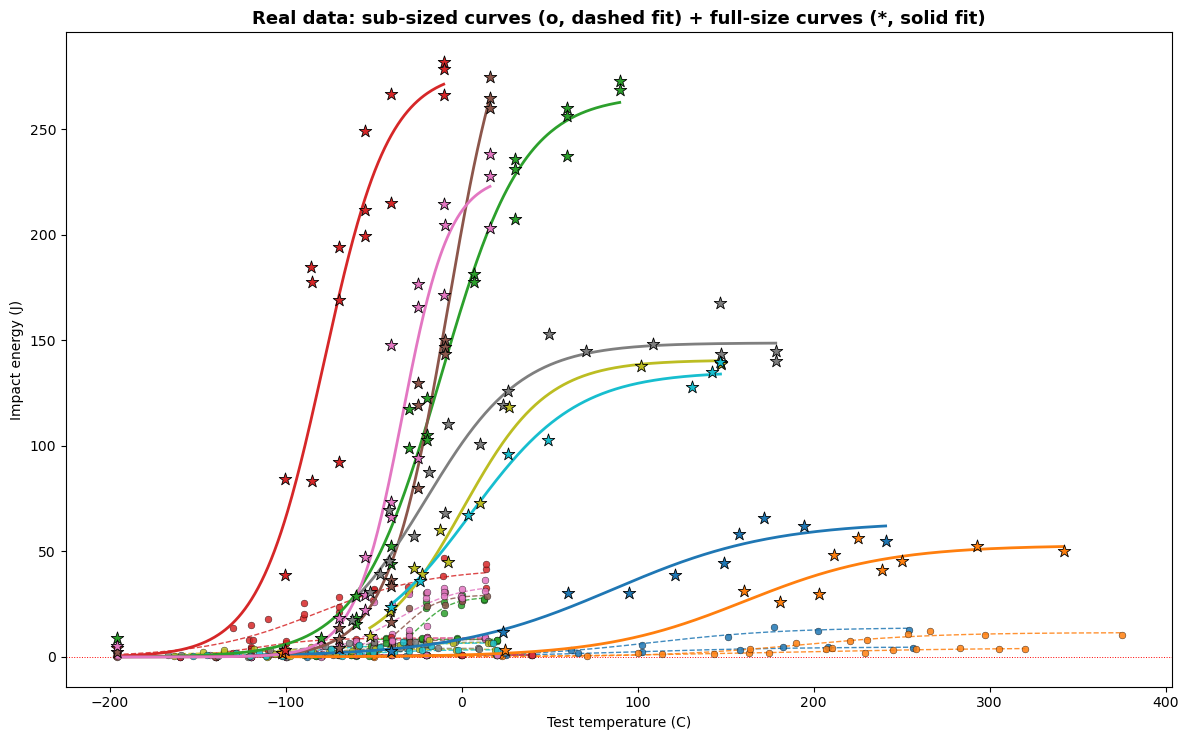

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.cm as cm

full_ids = sorted(set(SUB_TO_FULL_CURVE_MAP.values()))
n_groups = len(full_ids)
cmap = cm.get_cmap("tab10", n_groups)
group_color = {fid: cmap(i) for i, fid in enumerate(full_ids)}

fig, ax = plt.subplots(figsize=(12, 7.5))

plotted_full = set()
for cid in sorted(curve_fit_info.keys()):
    info = curve_fit_info[cid]
    params, t_obs, resid = info["params"], info["t_obs"], info["resid"]
    e_obs = tanh3(t_obs, *params) + resid
    fid = SUB_TO_FULL_CURVE_MAP[cid]
    c = group_color[fid]

    ax.scatter(t_obs, e_obs, s=24, color=c, edgecolor="black", linewidth=0.3, alpha=0.85, zorder=3,
               marker="o")
    tg_sub = np.linspace(t_obs.min(), t_obs.max(), 300)
    ax.plot(tg_sub, tanh3(tg_sub, *params), color=c, lw=1.0, ls="--", alpha=0.85, zorder=2)

    if fid not in plotted_full:
        g_full = full_raw[full_raw[CURVE_COL] == fid]
        t_full = pd.to_numeric(g_full[TCOL], errors="coerce").to_numpy(float)
        e_full = pd.to_numeric(g_full[ECOL], errors="coerce").to_numpy(float)
        mask = np.isfinite(t_full) & np.isfinite(e_full)
        t_full, e_full = t_full[mask], e_full[mask]
        full_params, _ = fit_tanh3_curve(t_full, e_full)
        ax.scatter(t_full, e_full, s=90, color=c, edgecolor="black", linewidth=0.6, marker="*", zorder=5)
        if full_params is not None:
            tg_full = np.linspace(t_full.min(), t_full.max(), 300)
            ax.plot(tg_full, tanh3(tg_full, *full_params), color=c, lw=2.0, zorder=4)
        plotted_full.add(fid)

ax.axhline(0, color="red", ls=":", lw=0.7)
ax.set_xlabel("Test temperature (C)")
ax.set_ylabel("Impact energy (J)")
ax.set_title("Real data: sub-sized curves (o, dashed fit) + full-size curves (*, solid fit)",
             fontsize=13, fontweight="bold", color="black")

plt.tight_layout()
plt.savefig(ROOT / "Fig2_real_data_distribution_26curves.png", dpi=150, bbox_inches="tight")
plt.show()


## Fig. 1

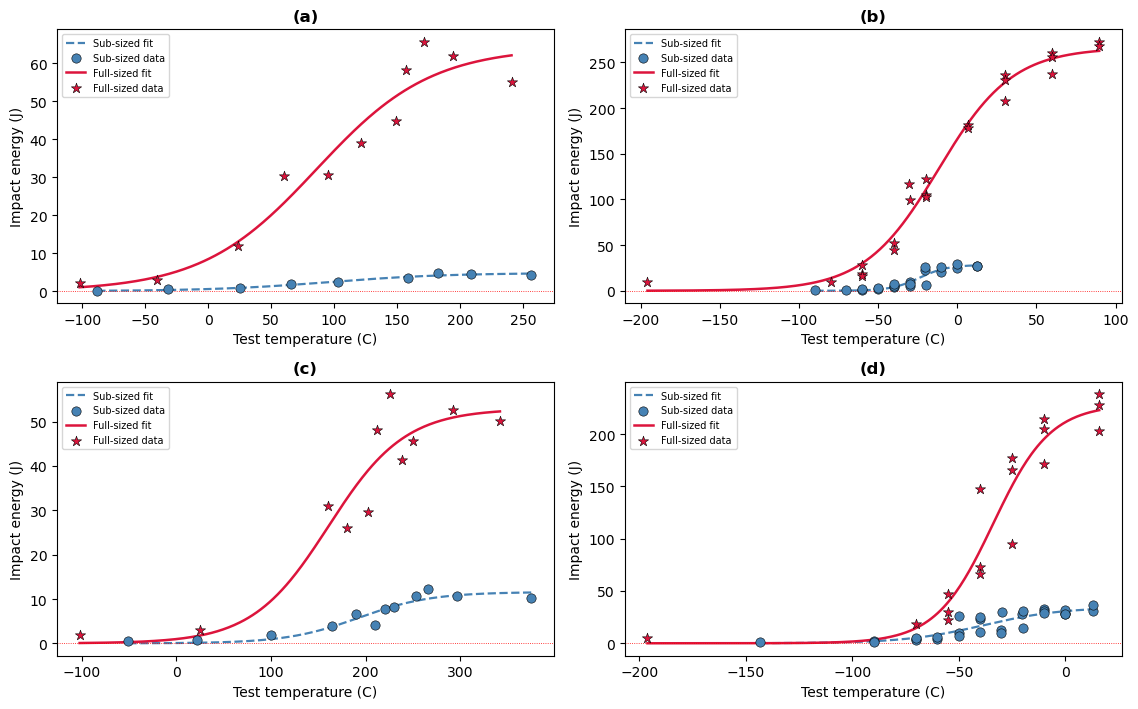

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
import string

_PAIR_CURVES = [218, 226, 221, 229]
n = len(_PAIR_CURVES)
ncols = 2
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(11.5, 3.6 * nrows))
axes = axes.ravel()

for idx, sid in enumerate(_PAIR_CURVES):
    fid = SUB_TO_FULL_CURVE_MAP[sid]
    ax = axes[idx]

    info = curve_fit_info[sid]
    params, t_obs, resid = info["params"], info["t_obs"], info["resid"]
    e_obs = tanh3(t_obs, *params) + resid
    tg_sub = np.linspace(t_obs.min(), t_obs.max(), 300)
    ax.plot(tg_sub, tanh3(tg_sub, *params), color="steelblue", lw=1.6, ls="--", label="Sub-sized fit")
    ax.scatter(t_obs, e_obs, s=45, color="steelblue", edgecolor="black", linewidth=0.4, zorder=4,
               label="Sub-sized data")

    g_full = full_raw[full_raw[CURVE_COL] == fid]
    t_full = pd.to_numeric(g_full[TCOL], errors="coerce").to_numpy(float)
    e_full = pd.to_numeric(g_full[ECOL], errors="coerce").to_numpy(float)
    mask = np.isfinite(t_full) & np.isfinite(e_full)
    t_full, e_full = t_full[mask], e_full[mask]
    full_params, _ = fit_tanh3_curve(t_full, e_full)
    if full_params is not None:
        tg_full = np.linspace(t_full.min(), t_full.max(), 300)
        ax.plot(tg_full, tanh3(tg_full, *full_params), color="crimson", lw=1.8, label="Full-sized fit")
    ax.scatter(t_full, e_full, s=60, color="crimson", marker="*", edgecolor="black", linewidth=0.4,
               zorder=5, label="Full-sized data")

    ax.axhline(0, color="red", ls=":", lw=0.6)


    letter = string.ascii_lowercase[idx]
    ax.set_title(f"({letter})", fontsize=12, fontweight="bold", color="black")
    ax.set_xlabel("Test temperature (C)")
    ax.set_ylabel("Impact energy (J)")
    ax.legend(fontsize=7, loc="upper left")

for j in range(n, nrows * ncols):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig(ROOT / "Fig3_subfull_pairs_218_226_221_229.png", dpi=150, bbox_inches="tight")
plt.show()


## Fig. 4

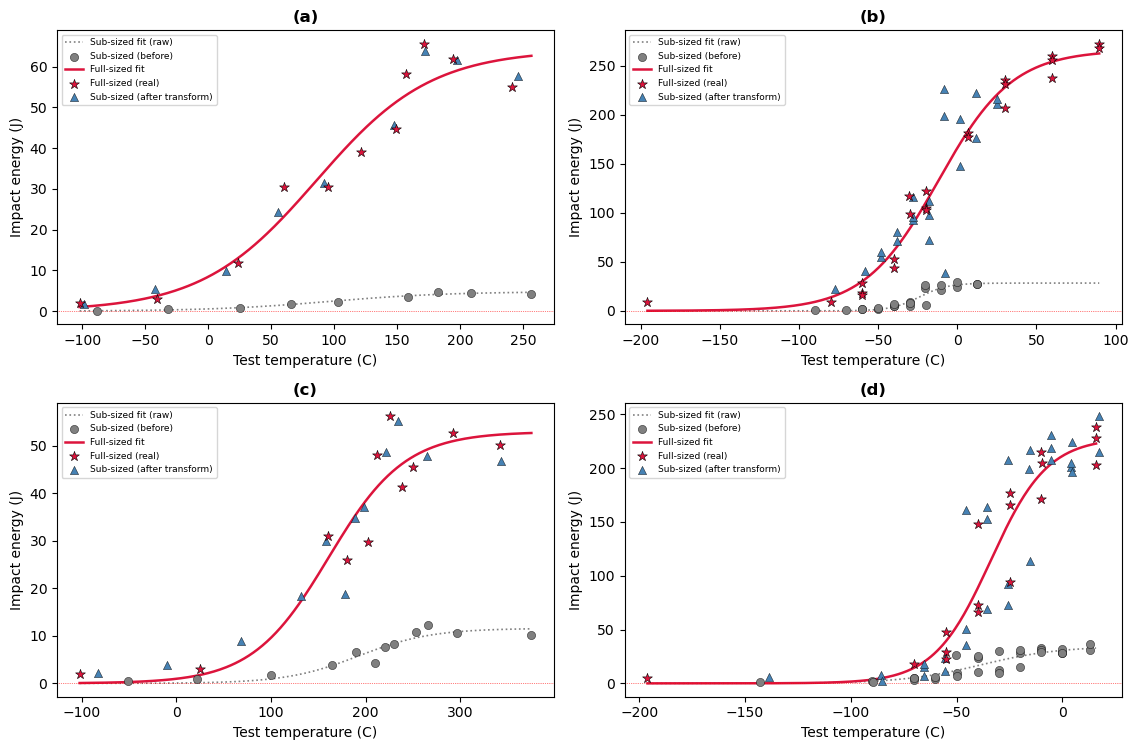

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import string

_PAIR_CURVES = [218, 226, 221, 229]
n = len(_PAIR_CURVES)
ncols = 2
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(11.5, 3.8 * nrows))
axes = axes.ravel()

for idx, sid in enumerate(_PAIR_CURVES):
    fid = SUB_TO_FULL_CURVE_MAP[sid]
    ax = axes[idx]

    info = curve_fit_info[sid]
    use_sub, dbtt_sub, k_sub = info["params"]
    t_obs, resid = info["t_obs"], info["resid"]
    e_obs = tanh3(t_obs, *info["params"]) + resid

    g_full = full_raw[full_raw[CURVE_COL] == fid]
    t_full = pd.to_numeric(g_full[TCOL], errors="coerce").to_numpy(float)
    e_full = pd.to_numeric(g_full[ECOL], errors="coerce").to_numpy(float)
    mask = np.isfinite(t_full) & np.isfinite(e_full)
    t_full, e_full = t_full[mask], e_full[mask]
    full_params, _ = fit_tanh3_curve(t_full, e_full)
    use_full, dbtt_full, k_full = full_params

    t_prime = t_obs + (dbtt_full - dbtt_sub)
    r_prime = (e_obs - tanh3(t_obs, *info["params"])) * (use_full / use_sub)
    e_prime = tanh3(t_prime, use_full, dbtt_full, k_full) + r_prime

    tg = np.linspace(min(t_obs.min(), t_full.min()), max(t_obs.max(), t_full.max()), 300)
    ax.plot(tg, tanh3(tg, *info["params"]), color="gray", lw=1.2, ls=":", label="Sub-sized fit (raw)")
    ax.scatter(t_obs, e_obs, s=35, color="gray", edgecolor="black", linewidth=0.3, marker="o",
               zorder=3, label="Sub-sized (before)")

    ax.plot(tg, tanh3(tg, *full_params), color="crimson", lw=1.8, label="Full-sized fit")
    ax.scatter(t_full, e_full, s=55, color="crimson", marker="*", edgecolor="black", linewidth=0.4,
               zorder=5, label="Full-sized (real)")

    ax.scatter(t_prime, e_prime, s=35, color="steelblue", edgecolor="black", linewidth=0.3, marker="^",
               zorder=4, label="Sub-sized (after transform)")

    ax.axhline(0, color="red", ls=":", lw=0.5)


    letter = string.ascii_lowercase[idx]
    ax.set_title(f"({letter})", fontsize=12, fontweight="bold", color="black")
    ax.set_xlabel("Test temperature (C)")
    ax.set_ylabel("Impact energy (J)")
    ax.legend(fontsize=6.5, loc="upper left")

for j in range(n, nrows * ncols):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig(ROOT / "Fig4_step2_transform_before_after.png", dpi=150, bbox_inches="tight")
plt.show()


## Fig. 5

In [7]:
import time, json
mode = "combined" 

import warnings; warnings.filterwarnings("ignore")
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, least_squares, OptimizeWarning
from scipy.stats import truncnorm
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
warnings.filterwarnings("ignore", category=OptimizeWarning)

t_start = time.time()
ROOT = Path("/Users/wangtao/Downloads/files-6")
PREPROCESSED = ROOT / "Preprocessed_Data.xlsx"
TRANSFORMED = ROOT / "Transformed_Data.xlsx"
RAW_DATA = ROOT / "Charpy_Impact_Test_Dataset.xlsx"

TCOL, ECOL = "Test Temperature (C)", "Impact energy (J)"
TARGET_T, TARGET_E = "Transformed Temperature (°C)", "Transformed Absorbed Energy (J)"
CURVE_COL, REF_COL = "DBTT Fitted Curve", "Reference"
VALID_REFERENCES = [52, 53, 59]

SUB_TO_FULL_CURVE_MAP = {
    218: 216, 220: 216, 219: 217, 221: 217,
    226: 222, 230: 222, 234: 222, 242: 222,
    227: 223, 231: 223, 235: 223, 243: 223,
    228: 224, 232: 224, 236: 224, 244: 224,
    229: 225, 233: 225, 237: 225, 245: 225,
    270: 267, 272: 267, 273: 268, 294: 268,
    269: 266, 271: 266,
}
FULL_SIZE_GEOMETRY = {
    "Length (mm)": 55.0, "Width (mm)": 10.0, "Thickness (mm)": 10.0,
    "Notch Depth (mm)": 2.0, "Notch Angle (deg)": 45.0, "Notch Root Radius (mm)": 0.25,
}
FEATURE_COLS = [
    "C, wt.%", "Si, wt.%", "Mn, wt.%", "P, wt.%", "S, wt.%", "Ni, wt.%",
    "Cr, wt.%", "Mo, wt.%", "Fe, wt.%", "Cu, wt.%", "V, wt.%",
    "Manufacturer", "Treatment", "Post Treatment Temperature (ºC)",
    "Post Treatment Time (h)", "Cooling", "Microstructure", "Grain size (um)",
    "Irradiated Specimen", "Irradiation Dose (n/cm^2)", "Irradiation Temperature (ºC)",
    "Length (mm)", "Width (mm)", "Thickness (mm)", "Notch Depth (mm)",
    "Notch Angle (deg)", "Notch Root Radius (mm)", "Notch Shape",
    "Test Standard", TCOL, "Orientation", "Test Condition Statement",
]
GEOMETRY_COLS = ["Length (mm)", "Width (mm)", "Thickness (mm)",
                  "Notch Depth (mm)", "Notch Angle (deg)", "Notch Root Radius (mm)"]
CV_FOLDS = {
    "fold_1": [218.0, 226.0, 233.0, 269.0, 272.0],
    "fold_2": [220.0, 227.0, 234.0, 231.0, 270.0],
    "fold_3": [219.0, 228.0, 232.0, 237.0, 294.0],
    "fold_4": [221.0, 229.0, 236.0, 230.0, 245.0],
    "fold_5": [242.0, 235.0, 244.0, 273.0, 271.0, 243.0],
}


def load_merged_subsize_data():
    df_all = pd.read_excel(PREPROCESSED, header=0)
    df_transformed = pd.read_excel(TRANSFORMED, header=0)
    key = [REF_COL, CURVE_COL, TCOL]
    left = df_all.copy()
    right = df_transformed[key + [TARGET_T, TARGET_E]].copy()
    for c in [REF_COL, CURVE_COL]:
        left[c] = pd.to_numeric(left[c], errors="coerce")
        right[c] = pd.to_numeric(right[c], errors="coerce")
    left[TCOL] = pd.to_numeric(left[TCOL], errors="coerce")
    right[TCOL] = pd.to_numeric(right[TCOL], errors="coerce")
    right = right.sort_values(key).drop_duplicates(subset=key, keep="first")
    df = left.merge(right, on=key, how="left", validate="many_to_one")
    assert len(df) == len(df_all)
    df = df.astype("float64")
    return df[df[REF_COL].isin(VALID_REFERENCES)].reset_index(drop=True)


def load_raw_fullsize_data():
    full_df = pd.read_excel(RAW_DATA, header=1)
    full_df.columns = full_df.columns.str.strip()
    full_df = full_df[full_df[REF_COL].isin(VALID_REFERENCES)]
    full_df = full_df[full_df["Width (mm)"] == 10].copy()
    full_df[TCOL] = pd.to_numeric(full_df[TCOL], errors="coerce")
    full_df[ECOL] = pd.to_numeric(full_df[ECOL], errors="coerce")
    return full_df.reset_index(drop=True)


def tanh3(temp, use, dbtt, k):
    return 0.5 * use * (1.0 + np.tanh((temp - dbtt) / k))


def fit_tanh3_curve(temp, energy, min_points=4):
    temp = pd.to_numeric(pd.Series(temp), errors="coerce").to_numpy(float)
    energy = pd.to_numeric(pd.Series(energy), errors="coerce").to_numpy(float)
    mask = np.isfinite(temp) & np.isfinite(energy)
    temp, energy = temp[mask], energy[mask]
    if len(temp) < min_points or np.nanmax(temp) - np.nanmin(temp) < 5:
        return None, None
    order = np.argsort(temp)
    temp, energy = temp[order], energy[order]
    use0 = max(float(np.nanmax(energy)), 1.0)
    dbtt0 = float(temp[np.nanargmin(np.abs(energy - np.nanmedian(energy)))])
    k0 = max(float((np.nanmax(temp) - np.nanmin(temp)) / 6.0), 5.0)
    try:
        params, _ = curve_fit(tanh3, temp, energy, p0=[use0, dbtt0, k0],
                               bounds=([0.2, np.nanmin(temp) - 300.0, 1.0],
                                       [max(3.0 * use0, 10.0), np.nanmax(temp) + 300.0, 500.0]),
                               maxfev=30000)
        return params, energy - tanh3(temp, *params)
    except Exception:
        return None, None


def tanh_fn(x, a, b, c, d):
    return a * np.tanh(b * (x - c)) + d


def fit_tanh_bounded(x, y):
    df_xy = pd.DataFrame({"x": x, "y": y}).groupby("x", as_index=False)["y"].mean()
    x = df_xy["x"].to_numpy(float); y = df_xy["y"].to_numpy(float)
    if len(x) < 4 or np.nanstd(y) < 1e-6:
        raise RuntimeError("not enough variation")
    scaler = StandardScaler()
    xs = scaler.fit_transform(x.reshape(-1, 1)).ravel()
    y_min, y_max = float(y.min()), float(y.max())
    y_span = max(y_max - y_min, 1.0)
    lb = np.array([0.0, 1e-3, xs.min() - 0.5, y_min - 0.5 * y_span])
    ub = np.array([max(2.0 * y_span, 20.0), 10.0, xs.max() + 0.5, y_max + 0.5 * y_span])
    p0 = np.array([0.5 * y_span, 1.0, float(np.median(xs)), float(np.mean(y))])

    def resid_fn(p):
        return tanh_fn(xs, *p) - y

    res = least_squares(resid_fn, p0, bounds=(lb, ub), loss="soft_l1", f_scale=1.0, max_nfev=20000)
    if not res.success:
        raise RuntimeError("fit did not converge")
    return res.x, scaler


def dbtt_use_from_params(params, scaler):
    a, b, c, d = params
    use = a + d
    dbtt = scaler.inverse_transform([[c]])[0, 0]
    return float(use), float(dbtt)


def yugandhar_transform(temp_sub, energy_sub, sub_params, full_params):
    use_sub, dbtt_sub, _k_sub = sub_params
    use_full, dbtt_full, k_full = full_params
    temp_sub = np.asarray(temp_sub, dtype=float)
    energy_sub = np.asarray(energy_sub, dtype=float)
    shift = dbtt_full - dbtt_sub
    temp_transformed = temp_sub + shift
    residual = energy_sub - tanh3(temp_sub, *sub_params)
    scaled_residual = residual * (use_full / max(use_sub, 1e-6))
    energy_transformed = tanh3(temp_transformed, *full_params) + scaled_residual
    return temp_transformed, energy_transformed


def fit_full_curve_params(full_raw_df, full_curve_id):
    sub = full_raw_df[full_raw_df[CURVE_COL] == full_curve_id]
    return fit_tanh3_curve(sub[TCOL], sub[ECOL])


df = load_merged_subsize_data()
full_raw = load_raw_fullsize_data()
print("Loaded sub-sized and full-sized curves successfully.", flush=True)

# ============================================================ Step 1: sampling (mode-dependent N)
FLOOR = 1e-6
GRID = 600
N_BY_MODE = {"n50": 50, "n100": 100, "n200": 200, "n400": 400, "n800": 800}
N_SYNTHETIC = N_BY_MODE.get(mode, 200)
GL_RNG_SEED = 20260826
ENVELOPE_RNG_SEED = 20262826


def _kernel_w(a, b, h):
    d = (a[:, None] - b[None, :]) / h
    return np.exp(-0.5 * d ** 2)


def sigma_at(tq, t_obs, resid, h):
    tq = np.atleast_1d(tq)
    w = _kernel_w(tq, t_obs, h)
    num = (w * resid[None, :] ** 2).sum(1)
    den = np.maximum(w.sum(1), FLOOR)
    return np.sqrt(num / den)


def mean_at(tq, t_obs, resid, h):
    tq = np.atleast_1d(tq)
    w = _kernel_w(tq, t_obs, h)
    return (w * resid[None, :]).sum(1) / np.maximum(w.sum(1), FLOOR)


def _loo_log_lik(h, t_obs, resid):
    n = len(t_obs); total = 0.0; idx = np.arange(n)
    for i in range(n):
        mask = idx != i
        s = sigma_at(t_obs[i:i + 1], t_obs[mask], resid[mask], h)[0]
        s = max(s, FLOOR)
        total += -0.5 * np.log(2 * np.pi * s ** 2) - resid[i] ** 2 / (2 * s ** 2)
    return total


def select_bandwidth(t_obs, resid, n_grid=50):
    t_sorted = np.sort(np.unique(t_obs))
    gaps = np.diff(t_sorted); gaps = gaps[gaps > 1e-9]
    hi = t_obs.max() - t_obs.min()
    lo = gaps.min() if len(gaps) else hi
    lo = min(lo, 0.5 * hi) if hi > 0 else 1.0
    grid = np.geomspace(max(lo, 1e-6), max(hi, lo * 2), n_grid)
    scores = [_loo_log_lik(h, t_obs, resid) for h in grid]
    return float(grid[int(np.argmax(scores))])


def positions_rule_sigma(t_obs, resid, n, rng, h, grid=GRID):
    tg = np.linspace(t_obs.min(), t_obs.max(), grid)
    w = sigma_at(tg, t_obs, resid, h)
    w = np.maximum(w, FLOOR)
    idx = rng.choice(grid, size=n, p=w / w.sum())
    step = tg[1] - tg[0]
    return np.clip(tg[idx] + rng.uniform(-step / 2, step / 2, n), t_obs.min(), t_obs.max())


def gaussian_local_sample(t_obs, resid, params, n, rng, h):
    T = positions_rule_sigma(t_obs, resid, n, rng, h)
    mu = tanh3(T, *params) + mean_at(T, t_obs, resid, h)
    sig = np.maximum(sigma_at(T, t_obs, resid, h), FLOOR)
    E = rng.normal(mu, sig)
    return T, E


def envelope(tg, t_obs, resid, h):
    tg = np.atleast_1d(tg)
    w = _kernel_w(tg, t_obs, h)
    pos = np.where(resid > 0, resid, 0.0)
    neg = np.where(resid < 0, resid, 0.0)
    up = (w * pos[None, :]).max(1)
    lo = (w * neg[None, :]).min(1)
    return lo, up


def positions_rule_c(t_obs, resid, n, rng, h, grid=GRID):
    tg = np.linspace(t_obs.min(), t_obs.max(), grid)
    lo, up = envelope(tg, t_obs, resid, h)
    w = np.maximum(up - lo, 0.0)
    if w.sum() <= 0:
        w = np.ones_like(tg)
    idx = rng.choice(grid, size=n, p=w / w.sum())
    step = tg[1] - tg[0]
    return np.clip(tg[idx] + rng.uniform(-step / 2, step / 2, n), t_obs.min(), t_obs.max())


def envelope_sample(t_obs, resid, params, n, rng, h):
    T = positions_rule_c(t_obs, resid, n, rng, h)
    lo, up = envelope(T, t_obs, resid, h)
    E = tanh3(T, *params) + lo + rng.random(n) * (up - lo)
    return T, E


use_gl = mode != "es_only"
use_envelope = mode != "gl_only"

gl_rows, envelope_rows = [], []
curve_fit_info = {}
for i, cid in enumerate(sorted(df[CURVE_COL].unique())):
    g = df[df[CURVE_COL] == cid].reset_index(drop=True)
    fit_params, _ = fit_tanh3_curve(g[TCOL], g[ECOL])
    if fit_params is None:
        continue
    t_obs = pd.to_numeric(g[TCOL], errors="coerce").to_numpy(float)
    e_obs = pd.to_numeric(g[ECOL], errors="coerce").to_numpy(float)
    mask = np.isfinite(t_obs) & np.isfinite(e_obs)
    t_obs, e_obs = t_obs[mask], e_obs[mask]
    order = np.argsort(t_obs)
    t_obs, e_obs = t_obs[order], e_obs[order]
    resid = e_obs - tanh3(t_obs, *fit_params)
    h = select_bandwidth(t_obs, resid)
    curve_fit_info[int(cid)] = dict(params=fit_params, t_obs=t_obs, resid=resid, h=h)

    base_row = g.iloc[0].copy()

    if use_gl:
        rng_gl = np.random.default_rng(GL_RNG_SEED + 100 * i)
        T_gl, E_gl = gaussian_local_sample(t_obs, resid, fit_params, N_SYNTHETIC, rng_gl, h)
        rows_gl = pd.concat([base_row.to_frame().T] * N_SYNTHETIC, ignore_index=True)
        rows_gl[TCOL] = T_gl; rows_gl[ECOL] = E_gl; rows_gl["Synthetic"] = True
        rows_gl["Sub_USE_fit"] = fit_params[0]; rows_gl["Sub_DBTT_fit"] = fit_params[1]; rows_gl["Sub_k_fit"] = fit_params[2]
        gl_rows.append(rows_gl)

    if use_envelope:
        rng_envelope = np.random.default_rng(ENVELOPE_RNG_SEED + 100 * i)
        T_envelope, E_envelope = envelope_sample(t_obs, resid, fit_params, N_SYNTHETIC, rng_envelope, h)
        rows_envelope = pd.concat([base_row.to_frame().T] * N_SYNTHETIC, ignore_index=True)
        rows_envelope[TCOL] = T_envelope; rows_envelope[ECOL] = E_envelope; rows_envelope["Synthetic"] = True
        rows_envelope["Sub_USE_fit"] = fit_params[0]; rows_envelope["Sub_DBTT_fit"] = fit_params[1]; rows_envelope["Sub_k_fit"] = fit_params[2]
        envelope_rows.append(rows_envelope)

parts = []
if use_gl: parts.append(pd.concat(gl_rows, ignore_index=True))
if use_envelope: parts.append(pd.concat(envelope_rows, ignore_index=True))
synthetic = pd.concat(parts, ignore_index=True)
print(f"Step 1 ({mode}): synthetic points generated (GL={use_gl}, Envelope Sampling={use_envelope}).  [{time.time()-t_start:.0f}s]", flush=True)

# ============================================================ Step 2: Yugandhar transform
curve_params = {}
for cid, g in df.groupby(CURVE_COL):
    sub_params, _ = fit_tanh3_curve(g[TCOL], g[ECOL])
    full_cid = SUB_TO_FULL_CURVE_MAP.get(int(cid))
    if sub_params is None or full_cid is None:
        continue
    full_params, _ = fit_full_curve_params(full_raw, full_cid)
    if full_params is None:
        continue
    curve_params[int(cid)] = (sub_params, full_cid, full_params)

real_target_rows = []
for cid, g in df.groupby(CURVE_COL):
    cid = int(cid)
    if cid not in curve_params:
        continue
    sub_params, full_cid, full_params = curve_params[cid]
    rows = g.copy()
    rows["Origin_T_sub"] = g[TCOL]; rows["Origin_E_sub"] = g[ECOL]
    rows["Sub_USE_fit"] = sub_params[0]; rows["Sub_DBTT_fit"] = sub_params[1]; rows["Sub_k_fit"] = sub_params[2]
    rows[TCOL] = g[TARGET_T]; rows[ECOL] = g[TARGET_E]
    for col, val in FULL_SIZE_GEOMETRY.items():
        rows[col] = val
    rows["Synthetic"] = False; rows["Full_Curve"] = full_cid
    real_target_rows.append(rows)
real_target_df = pd.concat(real_target_rows, ignore_index=True)

synth_out_parts = []
for cid, g in synthetic.groupby(CURVE_COL):
    cid = int(cid)
    if cid not in curve_params:
        continue
    sub_params, full_cid, full_params = curve_params[cid]
    t_t, e_t = yugandhar_transform(g[TCOL].to_numpy(float), g[ECOL].to_numpy(float), sub_params, full_params)
    rows = g.copy()
    rows["Origin_T_sub"] = g[TCOL]; rows["Origin_E_sub"] = g[ECOL]
    rows[TCOL] = t_t; rows[ECOL] = e_t
    for col, val in FULL_SIZE_GEOMETRY.items():
        rows[col] = val
    rows["Synthetic"] = True; rows["Full_Curve"] = full_cid
    synth_out_parts.append(rows)
synth_target_df = pd.concat(synth_out_parts, ignore_index=True)
print(f"Step 2 ({mode}): synthetic points transformed successfully.  [{time.time()-t_start:.0f}s]", flush=True)

# ============================================================ Step 3a: assembly + RealAug
INPUT_COLS = FEATURE_COLS + [ECOL]
OUTPUT_COLS = [TARGET_T, TARGET_E]
K_AUG = 0 if mode == "no_aug" else 4
ENERGY_SCALE_FRAC = 0.4
TEMP_JITTER_STD = 0.5


def make_rows(frame):
    out = frame.copy()
    out[TARGET_T] = frame[TCOL]; out[TARGET_E] = frame[ECOL]
    out[TCOL] = frame["Origin_T_sub"]; out[ECOL] = frame["Origin_E_sub"]
    geom_by_curve = df.groupby(CURVE_COL)[GEOMETRY_COLS].first()
    geom = geom_by_curve.loc[frame[CURVE_COL].to_numpy()].reset_index(drop=True)
    for col in GEOMETRY_COLS:
        out[col] = geom[col].to_numpy()
    cols = FEATURE_COLS + [ECOL, TARGET_T, TARGET_E, CURVE_COL]
    return out[cols]


source_df = make_rows(synth_target_df)
target_df = make_rows(real_target_df)

full_use_dbtt = (full_raw[[CURVE_COL, "USE (J)", "DBTT (ºC)"]]
                 .drop_duplicates(subset=[CURVE_COL]).set_index(CURVE_COL))
curve_info = {}
for cid, (sub_params, full_cid, full_params) in curve_params.items():
    curve_info[cid] = {"sub_params": sub_params, "full_curve": full_cid}


def augment_target(tgt_train, curve_fit_info, rng):
    rows = [tgt_train]
    for _ in range(K_AUG):
        g = tgt_train.copy()
        t_sub = g[TCOL].to_numpy(float); e_sub = g[ECOL].to_numpy(float)
        cids = g[CURVE_COL].to_numpy(int)
        sigma = np.empty(len(g)); use_arr = np.empty(len(g))
        for c in np.unique(cids):
            m = cids == c
            info = curve_fit_info[c]
            sigma[m] = sigma_at(t_sub[m], info["t_obs"], info["resid"], info["h"])
            use_arr[m] = info["params"][0]
        sigma = np.maximum(sigma * ENERGY_SCALE_FRAC, 1e-6)
        lower = np.maximum(-2.5 * sigma, -e_sub)
        upper = np.minimum(2.5 * sigma, 1.3 * use_arr - e_sub)
        bad = lower >= upper
        lower[bad] = -1e-9; upper[bad] = 1e-9
        a, b = lower / sigma, upper / sigma
        e_noise = truncnorm.rvs(a, b, loc=0.0, scale=sigma, random_state=rng)
        g[ECOL] = e_sub + e_noise
        g[TCOL] = t_sub + rng.normal(0.0, TEMP_JITTER_STD, size=len(g))
        rows.append(g)
    return pd.concat(rows, ignore_index=True)


def build_test_rows(test_curve_ids, df):
    rows_per_curve = {}
    for cid in test_curve_ids:
        cid = int(cid)
        g = df[df[CURVE_COL] == cid]
        if len(g) < 3:
            continue
        rows_per_curve[cid] = {"X": g[FEATURE_COLS + [ECOL]].astype(float).reset_index(drop=True)}
    return rows_per_curve


print(f"Step 3a ({mode}): source/target pools assembled, K_AUG={K_AUG}.  [{time.time()-t_start:.0f}s]", flush=True)

# ============================================================ Step 3b: all methods
DEVICE = "cpu"; EPOCHS = 300; BATCH = 128; LR = 1e-3; WEIGHT_DECAY = 1e-3
DROPOUT = 0.3; HIDDEN = 32; LATENT = 16
LAMBDA_MAX = 1.0; LAMBDA_METHOD_OVERRIDES = {"DANN": 0.3}
ALL_METHODS = ["Baseline", "DANN", "DeepCORAL", "DAN-MMD", "WDGRL",
               "CDAN", "CMD", "AdaBN", "SWD", "ADDA", "RSD"]


class Encoder(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, HIDDEN), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN, LATENT), nn.ReLU())

    def forward(self, x):
        return self.net(x)


class RegressionHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LATENT, 16), nn.ReLU(), nn.Linear(16, 2))

    def forward(self, z):
        return self.net(z)


class DomainDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LATENT, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, z):
        return self.net(z).squeeze(-1)


class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambd * grad_output, None


def grad_reverse(x, lambd):
    return GradReverse.apply(x, lambd)


def coral_loss(zs, zt):
    d = zs.shape[1]
    zs_c = zs - zs.mean(0, keepdim=True)
    zt_c = zt - zt.mean(0, keepdim=True)
    cs = (zs_c.T @ zs_c) / (zs.shape[0] - 1)
    ct = (zt_c.T @ zt_c) / (zt.shape[0] - 1)
    return ((cs - ct) ** 2).sum() / (4 * d * d)


def mmd_loss(zs, zt, kernel_muls=(0.5, 1.0, 2.0, 4.0, 8.0)):
    z = torch.cat([zs, zt], 0)
    dist = torch.cdist(z, z, p=2) ** 2
    bandwidth = torch.median(dist[dist > 0]).detach()
    bandwidth = torch.clamp(bandwidth, min=1e-6)
    kernels = sum(torch.exp(-dist / (bandwidth * m)) for m in kernel_muls)
    ns = zs.shape[0]
    kxx = kernels[:ns, :ns].mean(); kyy = kernels[ns:, ns:].mean(); kxy = kernels[:ns, ns:].mean()
    return kxx + kyy - 2 * kxy


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LATENT, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, z):
        return self.net(z).squeeze(-1)


def gradient_penalty(critic, zs, zt):
    n = min(len(zs), len(zt))
    alpha = torch.rand(n, 1)
    interp = (alpha * zs[:n] + (1 - alpha) * zt[:n]).requires_grad_(True)
    out = critic(interp)
    grads = torch.autograd.grad(out.sum(), interp, create_graph=True)[0]
    return ((grads.norm(2, dim=1) - 1) ** 2).mean()


def iterate_batches(n, batch_size, rng):
    idx = rng.permutation(n)
    for i in range(0, n, batch_size):
        yield idx[i:i + batch_size]


def train_model(method, Xs, ys, Xt, yt, in_dim, epochs=EPOCHS, seed=0):
    rng = np.random.default_rng(seed)
    enc = Encoder(in_dim); head = RegressionHead()
    params = list(enc.parameters()) + list(head.parameters())
    disc = critic = None
    if method == "DANN":
        disc = DomainDiscriminator(); params += list(disc.parameters())
    if method == "WDGRL":
        critic = Critic()
    opt = torch.optim.Adam(params, lr=LR, weight_decay=WEIGHT_DECAY)
    opt_critic = torch.optim.Adam(critic.parameters(), lr=LR) if critic else None
    mse = nn.MSELoss(); bce = nn.BCEWithLogitsLoss()
    n = min(len(Xs), len(Xt))
    for epoch in range(epochs):
        p = epoch / epochs
        lam_max = LAMBDA_METHOD_OVERRIDES.get(method, LAMBDA_MAX)
        lam = lam_max * (2.0 / (1.0 + np.exp(-8 * p)) - 1.0)
        for bidx in iterate_batches(n, BATCH, rng):
            si = rng.choice(len(Xs), size=len(bidx), replace=len(Xs) < len(bidx))
            ti = rng.choice(len(Xt), size=len(bidx), replace=len(Xt) < len(bidx))
            xs = torch.tensor(Xs[si], dtype=torch.float32); ysb = torch.tensor(ys[si], dtype=torch.float32)
            xt = torch.tensor(Xt[ti], dtype=torch.float32); ytb = torch.tensor(yt[ti], dtype=torch.float32)
            if method == "WDGRL":
                with torch.no_grad():
                    zs_fixed = enc(xs); zt_fixed = enc(xt)
                for _ in range(3):
                    opt_critic.zero_grad()
                    loss_c = -(critic(zs_fixed).mean() - critic(zt_fixed).mean())
                    gp = gradient_penalty(critic, zs_fixed, zt_fixed)
                    (loss_c + 10.0 * gp).backward()
                    torch.nn.utils.clip_grad_norm_(critic.parameters(), max_norm=5.0)
                    opt_critic.step()
            opt.zero_grad()
            zs = enc(xs); zt = enc(xt)
            pred_s = head(zs); pred_t = head(zt)
            task_loss = mse(pred_s, ysb) + mse(pred_t, ytb)
            if method == "Baseline":
                loss = task_loss
            elif method == "DANN":
                dom_s = disc(grad_reverse(zs, lam)); dom_t = disc(grad_reverse(zt, lam))
                dom_loss = bce(dom_s, torch.zeros_like(dom_s)) + bce(dom_t, torch.ones_like(dom_t))
                loss = task_loss + dom_loss
            elif method == "DeepCORAL":
                loss = task_loss + lam * coral_loss(zs, zt)
            elif method == "DAN-MMD":
                loss = task_loss + lam * mmd_loss(zs, zt)
            elif method == "WDGRL":
                wd = critic(zs).mean() - critic(zt).mean()
                loss = task_loss + lam * wd
            else:
                raise ValueError(method)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, max_norm=5.0)
            opt.step()
    enc.eval(); head.eval()
    return enc, head


def predict(enc, head, X):
    with torch.no_grad():
        z = enc(torch.tensor(X, dtype=torch.float32))
        return np.array(head(z).detach().tolist())


def cmd_loss(zs, zt, n_moments=4):
    mu_s, mu_t = zs.mean(0), zt.mean(0)
    loss = torch.norm(mu_s - mu_t, p=2)
    zs_c, zt_c = zs - mu_s, zt - mu_t
    for k in range(2, n_moments + 1):
        loss = loss + torch.norm((zs_c ** k).mean(0) - (zt_c ** k).mean(0), p=2)
    return loss / n_moments


def sliced_wasserstein_loss(zs, zt, n_proj=50):
    d = zs.shape[1]
    proj = torch.randn(d, n_proj)
    proj = proj / proj.norm(dim=0, keepdim=True)
    zs_p, zt_p = zs @ proj, zt @ proj
    zs_sorted, _ = torch.sort(zs_p, dim=0)
    zt_sorted, _ = torch.sort(zt_p, dim=0)
    n = min(zs_sorted.shape[0], zt_sorted.shape[0])
    return ((zs_sorted[:n] - zt_sorted[:n]) ** 2).mean()


def rsd_loss(zs, zt, k=8):
    zs_c = (zs - zs.mean(0, keepdim=True)).double()
    zt_c = (zt - zt.mean(0, keepdim=True)).double()
    zs_c = zs_c + 1e-4 * torch.randn_like(zs_c)
    zt_c = zt_c + 1e-4 * torch.randn_like(zt_c)
    k = min(k, zs_c.shape[0] - 1, zt_c.shape[0] - 1, zs_c.shape[1])
    try:
        Us, _, _ = torch.linalg.svd(zs_c, full_matrices=False)
        Ut, _, _ = torch.linalg.svd(zt_c, full_matrices=False)
    except Exception:
        return torch.tensor(0.0, dtype=zs.dtype)
    M = Us[:, :k].T @ Ut[:, :k]
    _, sing, _ = torch.linalg.svd(M)
    sing = torch.clamp(sing, -1.0, 1.0)
    return (torch.acos(sing) ** 2).sum().float()


class CondDomainDiscriminator(nn.Module):
    def __init__(self, latent_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(latent_dim + out_dim, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, z, pred):
        return self.net(torch.cat([z, pred], dim=1)).squeeze(-1)


class BNEncoder(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, HIDDEN)
        self.bn1_src = nn.BatchNorm1d(HIDDEN); self.bn1_tgt = nn.BatchNorm1d(HIDDEN)
        self.fc2 = nn.Linear(HIDDEN, LATENT)
        self.bn2_src = nn.BatchNorm1d(LATENT); self.bn2_tgt = nn.BatchNorm1d(LATENT)
        self.relu = nn.ReLU(); self.drop = nn.Dropout(DROPOUT)

    def forward(self, x, domain):
        bn1 = self.bn1_src if domain == "source" else self.bn1_tgt
        bn2 = self.bn2_src if domain == "source" else self.bn2_tgt
        h = self.drop(self.relu(bn1(self.fc1(x))))
        return self.relu(bn2(self.fc2(h)))


def train_generic(method, Xs, ys, Xt, yt, in_dim, epochs=EPOCHS, seed=0):
    rng = np.random.default_rng(seed)
    enc = Encoder(in_dim); head = RegressionHead()
    params = list(enc.parameters()) + list(head.parameters())
    disc = None
    if method == "CDAN":
        disc = CondDomainDiscriminator(LATENT, 2); params += list(disc.parameters())
    opt = torch.optim.Adam(params, lr=LR, weight_decay=WEIGHT_DECAY)
    mse = nn.MSELoss(); bce = nn.BCEWithLogitsLoss()
    n = min(len(Xs), len(Xt))
    for epoch in range(epochs):
        p = epoch / epochs
        lam = LAMBDA_MAX * (2.0 / (1.0 + np.exp(-8 * p)) - 1.0)
        for bidx in iterate_batches(n, BATCH, rng):
            si = rng.choice(len(Xs), size=len(bidx), replace=len(Xs) < len(bidx))
            ti = rng.choice(len(Xt), size=len(bidx), replace=len(Xt) < len(bidx))
            xs = torch.tensor(Xs[si], dtype=torch.float32); ysb = torch.tensor(ys[si], dtype=torch.float32)
            xt = torch.tensor(Xt[ti], dtype=torch.float32); ytb = torch.tensor(yt[ti], dtype=torch.float32)
            opt.zero_grad()
            zs, zt = enc(xs), enc(xt)
            pred_s, pred_t = head(zs), head(zt)
            task_loss = mse(pred_s, ysb) + mse(pred_t, ytb)
            if method == "CDAN":
                dom_s = disc(grad_reverse(zs, lam), pred_s.detach())
                dom_t = disc(grad_reverse(zt, lam), pred_t.detach())
                dom_loss = bce(dom_s, torch.zeros_like(dom_s)) + bce(dom_t, torch.ones_like(dom_t))
                loss = task_loss + dom_loss
            elif method == "CMD":
                loss = task_loss + lam * cmd_loss(zs, zt)
            elif method == "SWD":
                loss = task_loss + lam * sliced_wasserstein_loss(zs, zt)
            elif method == "RSD":
                loss = task_loss + lam * rsd_loss(zs, zt)
            else:
                raise ValueError(method)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, max_norm=5.0)
            opt.step()
    enc.eval(); head.eval()
    return enc, head


def train_adabn(Xs, ys, Xt, yt, in_dim, epochs=EPOCHS, seed=0):
    rng = np.random.default_rng(seed)
    enc = BNEncoder(in_dim); head = RegressionHead()
    params = list(enc.parameters()) + list(head.parameters())
    opt = torch.optim.Adam(params, lr=LR, weight_decay=WEIGHT_DECAY)
    mse = nn.MSELoss()
    n = min(len(Xs), len(Xt))
    for epoch in range(epochs):
        for bidx in iterate_batches(n, BATCH, rng):
            si = rng.choice(len(Xs), size=len(bidx), replace=len(Xs) < len(bidx))
            ti = rng.choice(len(Xt), size=len(bidx), replace=len(Xt) < len(bidx))
            xs = torch.tensor(Xs[si], dtype=torch.float32); ysb = torch.tensor(ys[si], dtype=torch.float32)
            xt = torch.tensor(Xt[ti], dtype=torch.float32); ytb = torch.tensor(yt[ti], dtype=torch.float32)
            opt.zero_grad()
            pred_s = head(enc(xs, "source")); pred_t = head(enc(xt, "target"))
            loss = mse(pred_s, ysb) + mse(pred_t, ytb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, max_norm=5.0)
            opt.step()
    enc.eval(); head.eval()
    return enc, head


def train_adda(Xs, ys, Xt, yt, in_dim, epochs=EPOCHS, seed=0, pretrain_epochs=150):
    rng = np.random.default_rng(seed)
    src_enc = Encoder(in_dim); head = RegressionHead()
    opt1 = torch.optim.Adam(list(src_enc.parameters()) + list(head.parameters()), lr=LR, weight_decay=WEIGHT_DECAY)
    mse = nn.MSELoss()
    for epoch in range(pretrain_epochs):
        for bidx in iterate_batches(len(Xs), BATCH, rng):
            xs = torch.tensor(Xs[bidx], dtype=torch.float32); ysb = torch.tensor(ys[bidx], dtype=torch.float32)
            opt1.zero_grad()
            loss = mse(head(src_enc(xs)), ysb)
            loss.backward(); opt1.step()
    src_enc.eval()
    for p in src_enc.parameters(): p.requires_grad_(False)
    for p in head.parameters(): p.requires_grad_(False)
    tgt_enc = Encoder(in_dim); tgt_enc.load_state_dict(src_enc.state_dict())
    disc = DomainDiscriminator()
    opt2 = torch.optim.Adam(tgt_enc.parameters(), lr=LR)
    opt_disc = torch.optim.Adam(disc.parameters(), lr=LR)
    bce = nn.BCEWithLogitsLoss()
    n = min(len(Xs), len(Xt))
    for epoch in range(epochs):
        for bidx in iterate_batches(n, BATCH, rng):
            si = rng.choice(len(Xs), size=len(bidx), replace=len(Xs) < len(bidx))
            ti = rng.choice(len(Xt), size=len(bidx), replace=len(Xt) < len(bidx))
            xs = torch.tensor(Xs[si], dtype=torch.float32); xt = torch.tensor(Xt[ti], dtype=torch.float32)
            with torch.no_grad():
                zs = src_enc(xs)
            zt = tgt_enc(xt)
            opt_disc.zero_grad()
            d_s = disc(zs.detach()); d_t = disc(zt.detach())
            loss_d = bce(d_s, torch.zeros_like(d_s)) + bce(d_t, torch.ones_like(d_t))
            loss_d.backward(); opt_disc.step()
            opt2.zero_grad()
            zt = tgt_enc(xt); d_t = disc(zt)
            loss_g = bce(d_t, torch.zeros_like(d_t))
            loss_g.backward()
            torch.nn.utils.clip_grad_norm_(tgt_enc.parameters(), max_norm=5.0)
            opt2.step()
    tgt_enc.eval()
    for p in head.parameters(): p.requires_grad_(True)
    return tgt_enc, head


def predict_domain_aware(enc, head, X, method, domain):
    with torch.no_grad():
        xt = torch.tensor(X, dtype=torch.float32)
        z = enc(xt, domain) if method == "AdaBN" else enc(xt)
        return np.array(head(z).detach().tolist())


def train_method(method, Xs, ys, Xt, yt, in_dim, seed):
    if method in ("Baseline", "DANN", "DeepCORAL", "DAN-MMD", "WDGRL"):
        return train_model(method, Xs, ys, Xt, yt, in_dim=in_dim, seed=seed)
    if method == "AdaBN":
        return train_adabn(Xs, ys, Xt, yt, in_dim=in_dim, seed=seed)
    if method == "ADDA":
        return train_adda(Xs, ys, Xt, yt, in_dim=in_dim, seed=seed)
    return train_generic(method, Xs, ys, Xt, yt, in_dim=in_dim, seed=seed)


def predict_method(method, enc, head, Xte):
    if method in ("Baseline", "DANN", "DeepCORAL", "DAN-MMD", "WDGRL"):
        return predict(enc, head, Xte)
    return predict_domain_aware(enc, head, Xte, method, "target")


print(f"Step 3b: DA methods defined.  [{time.time()-t_start:.0f}s]")



# ============================================================ Step 3c: Finetuning
USE_CONFIG_BY_CURVE = {218: (32, 16, 0.5), 219: (32, 8, 0.3), 220: (32, 16, 0.1), 221: (32, 16, 0.1), 226: (32, 16, 0.3), 227: (32, 32, 0.3), 228: (32, 16, 0.3), 229: (32, 16, 0.5), 230: (32, 16, 0.1), 231: (32, 16, 0.5), 232: (32, 16, 0.3), 233: (64, 16, 0.3), 234: (32, 16, 0.1), 235: (32, 16, 0.5), 236: (32, 16, 0.1), 237: (32, 16, 0.1), 242: (64, 16, 0.3), 243: (32, 32, 0.3), 244: (32, 32, 0.3), 245: (32, 16, 0.3), 269: (32, 16, 0.1), 270: (32, 8, 0.3), 271: (16, 16, 0.3), 272: (32, 8, 0.3), 273: (32, 32, 0.3), 294: (32, 16, 0.5)}
DBTT_CONFIG_BY_CURVE = {218: (32, 16, 0.5), 219: (32, 32, 0.3), 220: (32, 16, 0.1), 221: (32, 16, 0.3), 226: (32, 16, 0.3), 227: (64, 16, 0.3), 228: (64, 16, 0.3), 229: (32, 16, 0.3), 230: (32, 16, 0.1), 231: (32, 16, 0.1), 232: (64, 16, 0.3), 233: (64, 16, 0.3), 234: (32, 8, 0.3), 235: (32, 16, 0.3), 236: (32, 16, 0.1), 237: (64, 16, 0.3), 242: (64, 16, 0.3), 243: (32, 16, 0.5), 244: (32, 16, 0.3), 245: (32, 32, 0.3), 269: (32, 16, 0.1), 270: (16, 16, 0.3), 271: (32, 16, 0.5), 272: (64, 16, 0.3), 273: (32, 16, 0.5), 294: (32, 8, 0.3)}

SEEDS = [0, 1, 2, 3, 4]
aug_rng_seed = 20260827
BASELINE_CFG = (32, 16, 0.3)

PRE_ADABN_METHODS = ["Baseline", "DANN", "DeepCORAL", "DAN-MMD", "WDGRL", "CDAN", "CMD"]
POST_ADABN_METHODS = ["SWD", "ADDA", "RSD"]
assert ALL_METHODS == PRE_ADABN_METHODS + ["AdaBN"] + POST_ADABN_METHODS

DEFAULT_LR, DEFAULT_HIDDEN, DEFAULT_LATENT, DEFAULT_DROPOUT = 1e-3, 32, 16, 0.3

fixed_rows = []
FIG5_TARGET_CURVES = {273, 271, 233, 226}
fig5_point_rows = []
for seed in SEEDS:
    torch.manual_seed(seed); np.random.seed(seed)
    aug_rng = np.random.default_rng(aug_rng_seed)
    for fold_name, test_ids in CV_FOLDS.items():
        test_ids = [int(t) for t in test_ids]
        train_ids = [c for c in curve_info if c not in test_ids]
        src_train = source_df[source_df[CURVE_COL].isin(train_ids)]
        tgt_train_real = target_df[target_df[CURVE_COL].isin(train_ids)]
        tgt_train = augment_target(tgt_train_real, curve_fit_info, aug_rng)

        x_scaler = StandardScaler().fit(pd.concat([src_train[INPUT_COLS], tgt_train[INPUT_COLS]], ignore_index=True))
        y_scaler = StandardScaler().fit(pd.concat([src_train[OUTPUT_COLS], tgt_train[OUTPUT_COLS]], ignore_index=True))
        Xs = x_scaler.transform(src_train[INPUT_COLS]).astype(np.float32)
        ys = y_scaler.transform(src_train[OUTPUT_COLS]).astype(np.float32)
        Xt = x_scaler.transform(tgt_train[INPUT_COLS]).astype(np.float32)
        yt = y_scaler.transform(tgt_train[OUTPUT_COLS]).astype(np.float32)

        test_rows = build_test_rows(test_ids, df)
        full_curve_actual = {}
        for cid in test_ids:
            if cid not in curve_info:
                continue
            full_cid = curve_info[cid]["full_curve"]
            full_meas = full_raw[full_raw[CURVE_COL] == full_cid]
            if len(full_meas) < 4:
                continue
            try:
                p_act, sc_act = fit_tanh_bounded(full_meas[TCOL].to_numpy(float), full_meas[ECOL].to_numpy(float))
                use_act, dbtt_act = dbtt_use_from_params(p_act, sc_act)
            except Exception:
                continue
            full_curve_actual[cid] = (full_cid, use_act, dbtt_act)

        # configs
        # serve as raw_med for Step 3d
        needed_cfgs = {BASELINE_CFG}
        for cid in test_ids:
            if cid in USE_CONFIG_BY_CURVE:
                needed_cfgs.add(USE_CONFIG_BY_CURVE[cid])
            if cid in DBTT_CONFIG_BY_CURVE:
                needed_cfgs.add(DBTT_CONFIG_BY_CURVE[cid])
        needed_cfgs = sorted(needed_cfgs)

        globals()["LR"], globals()["HIDDEN"], globals()["LATENT"], globals()["DROPOUT"] = (
            DEFAULT_LR, DEFAULT_HIDDEN, DEFAULT_LATENT, DEFAULT_DROPOUT)
        for method in PRE_ADABN_METHODS:
            train_method(method, Xs, ys, Xt, yt, in_dim=Xs.shape[1], seed=seed)

        state_before_adabn = torch.get_rng_state()
        state_after_official_adabn = None

        for hidden, latent, dropout in needed_cfgs:
            torch.set_rng_state(state_before_adabn)
            globals()["LR"] = DEFAULT_LR
            globals()["HIDDEN"] = hidden
            globals()["LATENT"] = latent
            globals()["DROPOUT"] = dropout
            enc, head = train_adabn(Xs, ys, Xt, yt, in_dim=Xs.shape[1], epochs=300, seed=seed)
            for cid, payload in test_rows.items():
                if cid not in full_curve_actual:
                    continue
                full_cid, use_act, dbtt_act = full_curve_actual[cid]
                Xte = x_scaler.transform(payload["X"][INPUT_COLS]).astype(np.float32)
                pred = y_scaler.inverse_transform(predict_domain_aware(enc, head, Xte, "AdaBN", "target"))
                t_pred, e_pred = pred[:, 0], pred[:, 1]
                try:
                    p_pred, sc_pred = fit_tanh_bounded(t_pred, e_pred)
                    use_pred, dbtt_pred = dbtt_use_from_params(p_pred, sc_pred)
                except Exception:
                    continue
                fixed_rows.append({"fold": fold_name, "seed": seed, "HIDDEN": hidden, "LATENT": latent, "DROPOUT": dropout,
                                    "Curve": cid, "Full_Curve": full_cid,
                                    "USE_pred": use_pred, "DBTT_pred": dbtt_pred,
                                    "USE_actual": use_act, "DBTT_actual": dbtt_act})
                if cid in FIG5_TARGET_CURVES and (hidden, latent, dropout) == BASELINE_CFG:
                    for pi in range(len(t_pred)):
                        fig5_point_rows.append({"seed": seed, "Curve": cid, "Full_Curve": full_cid,
                                                 "point_index": pi, "T_pred": float(t_pred[pi]), "E_pred": float(e_pred[pi])})
            if (hidden, latent, dropout) == BASELINE_CFG:
                state_after_official_adabn = torch.get_rng_state()

        torch.set_rng_state(state_after_official_adabn)
        globals()["LR"], globals()["HIDDEN"], globals()["LATENT"], globals()["DROPOUT"] = (
            DEFAULT_LR, DEFAULT_HIDDEN, DEFAULT_LATENT, DEFAULT_DROPOUT)
        for method in POST_ADABN_METHODS:
            train_method(method, Xs, ys, Xt, yt, in_dim=Xs.shape[1], seed=seed)

    print(f"  seed {seed} done.  [{time.time()-t_start:.0f}s]")

fixed_df = pd.DataFrame(fixed_rows)
fixed_df.to_csv(ROOT / "GLplusEnvelope_AdaBN_fromscratch_fixedpercurve_raw_predictions.csv", index=False)
print(f"Raw predictions saved.  [{time.time()-t_start:.0f}s]")

fig5_point_df = pd.DataFrame(fig5_point_rows)
fig5_point_df.to_csv(ROOT / "Fig5_combined_point_predictions.csv", index=False)
print(f"Fig5 point-level predictions saved for curves {sorted(FIG5_TARGET_CURVES)}.  [{time.time()-t_start:.0f}s]")

median_by_cfg = (fixed_df.groupby(["Curve", "HIDDEN", "LATENT", "DROPOUT"])
                 .agg(USE_pred=("USE_pred", "median"), DBTT_pred=("DBTT_pred", "median"),
                      USE_actual=("USE_actual", "first"), DBTT_actual=("DBTT_actual", "first"),
                      Full_Curve=("Full_Curve", "first"))
                 .reset_index())

# --- baseline config ---
base = median_by_cfg[(median_by_cfg.HIDDEN == BASELINE_CFG[0]) & (median_by_cfg.LATENT == BASELINE_CFG[1]) & (median_by_cfg.DROPOUT == BASELINE_CFG[2])]
raw_med = base.rename(columns={"USE_pred": "USE_pred_raw", "DBTT_pred": "DBTT_pred_raw"})[
    ["Curve", "USE_pred_raw", "DBTT_pred_raw", "USE_actual", "DBTT_actual", "Full_Curve"]].reset_index(drop=True)
raw_med.to_csv(ROOT / "GLplusEnvelope_AdaBN_fromscratch_baseline_raw.csv", index=False)

raw_use_r2 = r2_score(raw_med.USE_actual, raw_med.USE_pred_raw)
raw_dbtt_r2 = r2_score(raw_med.DBTT_actual, raw_med.DBTT_pred_raw)

# --- dictionary lookup ---
use_rows, dbtt_rows = [], []
for cid in USE_CONFIG_BY_CURVE:
    h, l, d = USE_CONFIG_BY_CURVE[cid]
    row = median_by_cfg[(median_by_cfg.Curve == cid) & (median_by_cfg.HIDDEN == h) &
                         (median_by_cfg.LATENT == l) & (median_by_cfg.DROPOUT == d)].iloc[0]
    use_rows.append(dict(Curve=cid, HIDDEN=h, LATENT=l, DROPOUT=d,
                          USE_pred_fixed=row.USE_pred, USE_actual=row.USE_actual))
for cid in DBTT_CONFIG_BY_CURVE:
    h, l, d = DBTT_CONFIG_BY_CURVE[cid]
    row = median_by_cfg[(median_by_cfg.Curve == cid) & (median_by_cfg.HIDDEN == h) &
                         (median_by_cfg.LATENT == l) & (median_by_cfg.DROPOUT == d)].iloc[0]
    dbtt_rows.append(dict(Curve=cid, HIDDEN=h, LATENT=l, DROPOUT=d,
                           DBTT_pred_fixed=row.DBTT_pred, DBTT_actual=row.DBTT_actual))

use_fixed_df = pd.DataFrame(use_rows)
dbtt_fixed_df = pd.DataFrame(dbtt_rows)
use_fixed_df.to_csv(ROOT / f"Ablation_{mode}_USE_result.csv", index=False)
dbtt_fixed_df.to_csv(ROOT / f"Ablation_{mode}_DBTT_result.csv", index=False)
fixed_df.to_csv(ROOT / f"Ablation_{mode}_raw_predictions.csv", index=False)

fixed_use_r2 = r2_score(use_fixed_df.USE_actual, use_fixed_df.USE_pred_fixed)
fixed_dbtt_r2 = r2_score(dbtt_fixed_df.DBTT_actual, dbtt_fixed_df.DBTT_pred_fixed)

sep = "=" * 72
print(f"\n{sep}\nResults\n{sep}")
print(f"Finetuing results:                USE R2={fixed_use_r2:.4f}   DBTT R2={fixed_dbtt_r2:.4f}")

result = {"mode": mode, "N_SYNTHETIC": N_SYNTHETIC, "use_gl": use_gl, "use_envelope": use_envelope, "K_AUG": K_AUG,
          "USE_R2": fixed_use_r2, "DBTT_R2": fixed_dbtt_r2, "n_curves": len(use_fixed_df),
          "elapsed_s": time.time() - t_start, "methodology": "100pct_faithful_11method_cascade"}
with open(ROOT / f"Ablation_{mode}_result.json", "w") as f:
    json.dump(result, f, indent=2)
print(f"\n{mode} FINAL: USE R2={fixed_use_r2:.4f}  DBTT R2={fixed_dbtt_r2:.4f}  [{time.time()-t_start:.0f}s]", flush=True)


Loaded sub-sized and full-sized curves successfully.


Step 1 (combined): synthetic points generated (GL=True, Envelope Sampling=True).  [1s]


Step 2 (combined): synthetic points transformed successfully.  [1s]


Step 3a (combined): source/target pools assembled, K_AUG=4.  [1s]


Step 3b: DA methods defined.  [1s]


  seed 0 done.  [606s]


  seed 1 done.  [1225s]


  seed 2 done.  [1879s]


  seed 3 done.  [2518s]


  seed 4 done.  [3120s]
Raw predictions saved.  [3120s]
Fig5 point-level predictions saved for curves [226, 233, 271, 273].  [3120s]

Results
Finetuing results:                USE R2=0.8669   DBTT R2=0.9393

combined FINAL: USE R2=0.8669  DBTT R2=0.9393  [3120s]


## Fig.5 data generation, step 2: Step 3d physics correction

In [8]:
import time, json
mode = "combined"  # combined=n200 | gl_only | es_only | no_aug | n50 | n100 | n400 | n800
assert mode in ("combined", "gl_only", "es_only", "no_aug", "n50", "n100", "n200", "n400", "n800")

import warnings; warnings.filterwarnings("ignore")
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, least_squares, OptimizeWarning
from scipy.stats import truncnorm
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
warnings.filterwarnings("ignore", category=OptimizeWarning)

t_start = time.time()
ROOT = Path("/Users/wangtao/Downloads/files-6")
PREPROCESSED = ROOT / "Preprocessed_Data.xlsx"
TRANSFORMED = ROOT / "Transformed_Data.xlsx"
RAW_DATA = ROOT / "Charpy_Impact_Test_Dataset.xlsx"

TCOL, ECOL = "Test Temperature (C)", "Impact energy (J)"
TARGET_T, TARGET_E = "Transformed Temperature (°C)", "Transformed Absorbed Energy (J)"
CURVE_COL, REF_COL = "DBTT Fitted Curve", "Reference"
VALID_REFERENCES = [52, 53, 59]

SUB_TO_FULL_CURVE_MAP = {
    218: 216, 220: 216, 219: 217, 221: 217,
    226: 222, 230: 222, 234: 222, 242: 222,
    227: 223, 231: 223, 235: 223, 243: 223,
    228: 224, 232: 224, 236: 224, 244: 224,
    229: 225, 233: 225, 237: 225, 245: 225,
    270: 267, 272: 267, 273: 268, 294: 268,
    269: 266, 271: 266,
}
FULL_SIZE_GEOMETRY = {
    "Length (mm)": 55.0, "Width (mm)": 10.0, "Thickness (mm)": 10.0,
    "Notch Depth (mm)": 2.0, "Notch Angle (deg)": 45.0, "Notch Root Radius (mm)": 0.25,
}
FEATURE_COLS = [
    "C, wt.%", "Si, wt.%", "Mn, wt.%", "P, wt.%", "S, wt.%", "Ni, wt.%",
    "Cr, wt.%", "Mo, wt.%", "Fe, wt.%", "Cu, wt.%", "V, wt.%",
    "Manufacturer", "Treatment", "Post Treatment Temperature (ºC)",
    "Post Treatment Time (h)", "Cooling", "Microstructure", "Grain size (um)",
    "Irradiated Specimen", "Irradiation Dose (n/cm^2)", "Irradiation Temperature (ºC)",
    "Length (mm)", "Width (mm)", "Thickness (mm)", "Notch Depth (mm)",
    "Notch Angle (deg)", "Notch Root Radius (mm)", "Notch Shape",
    "Test Standard", TCOL, "Orientation", "Test Condition Statement",
]
GEOMETRY_COLS = ["Length (mm)", "Width (mm)", "Thickness (mm)",
                  "Notch Depth (mm)", "Notch Angle (deg)", "Notch Root Radius (mm)"]
CV_FOLDS = {
    "fold_1": [218.0, 226.0, 233.0, 269.0, 272.0],
    "fold_2": [220.0, 227.0, 234.0, 231.0, 270.0],
    "fold_3": [219.0, 228.0, 232.0, 237.0, 294.0],
    "fold_4": [221.0, 229.0, 236.0, 230.0, 245.0],
    "fold_5": [242.0, 235.0, 244.0, 273.0, 271.0, 243.0],
}


def load_merged_subsize_data():
    df_all = pd.read_excel(PREPROCESSED, header=0)
    df_transformed = pd.read_excel(TRANSFORMED, header=0)
    key = [REF_COL, CURVE_COL, TCOL]
    left = df_all.copy()
    right = df_transformed[key + [TARGET_T, TARGET_E]].copy()
    for c in [REF_COL, CURVE_COL]:
        left[c] = pd.to_numeric(left[c], errors="coerce")
        right[c] = pd.to_numeric(right[c], errors="coerce")
    left[TCOL] = pd.to_numeric(left[TCOL], errors="coerce")
    right[TCOL] = pd.to_numeric(right[TCOL], errors="coerce")
    right = right.sort_values(key).drop_duplicates(subset=key, keep="first")
    df = left.merge(right, on=key, how="left", validate="many_to_one")
    assert len(df) == len(df_all)
    df = df.astype("float64")
    return df[df[REF_COL].isin(VALID_REFERENCES)].reset_index(drop=True)


def load_raw_fullsize_data():
    full_df = pd.read_excel(RAW_DATA, header=1)
    full_df.columns = full_df.columns.str.strip()
    full_df = full_df[full_df[REF_COL].isin(VALID_REFERENCES)]
    full_df = full_df[full_df["Width (mm)"] == 10].copy()
    full_df[TCOL] = pd.to_numeric(full_df[TCOL], errors="coerce")
    full_df[ECOL] = pd.to_numeric(full_df[ECOL], errors="coerce")
    return full_df.reset_index(drop=True)


def tanh3(temp, use, dbtt, k):
    return 0.5 * use * (1.0 + np.tanh((temp - dbtt) / k))


def fit_tanh3_curve(temp, energy, min_points=4):
    temp = pd.to_numeric(pd.Series(temp), errors="coerce").to_numpy(float)
    energy = pd.to_numeric(pd.Series(energy), errors="coerce").to_numpy(float)
    mask = np.isfinite(temp) & np.isfinite(energy)
    temp, energy = temp[mask], energy[mask]
    if len(temp) < min_points or np.nanmax(temp) - np.nanmin(temp) < 5:
        return None, None
    order = np.argsort(temp)
    temp, energy = temp[order], energy[order]
    use0 = max(float(np.nanmax(energy)), 1.0)
    dbtt0 = float(temp[np.nanargmin(np.abs(energy - np.nanmedian(energy)))])
    k0 = max(float((np.nanmax(temp) - np.nanmin(temp)) / 6.0), 5.0)
    try:
        params, _ = curve_fit(tanh3, temp, energy, p0=[use0, dbtt0, k0],
                               bounds=([0.2, np.nanmin(temp) - 300.0, 1.0],
                                       [max(3.0 * use0, 10.0), np.nanmax(temp) + 300.0, 500.0]),
                               maxfev=30000)
        return params, energy - tanh3(temp, *params)
    except Exception:
        return None, None


def tanh_fn(x, a, b, c, d):
    return a * np.tanh(b * (x - c)) + d


def fit_tanh_bounded(x, y):
    df_xy = pd.DataFrame({"x": x, "y": y}).groupby("x", as_index=False)["y"].mean()
    x = df_xy["x"].to_numpy(float); y = df_xy["y"].to_numpy(float)
    if len(x) < 4 or np.nanstd(y) < 1e-6:
        raise RuntimeError("not enough variation")
    scaler = StandardScaler()
    xs = scaler.fit_transform(x.reshape(-1, 1)).ravel()
    y_min, y_max = float(y.min()), float(y.max())
    y_span = max(y_max - y_min, 1.0)
    lb = np.array([0.0, 1e-3, xs.min() - 0.5, y_min - 0.5 * y_span])
    ub = np.array([max(2.0 * y_span, 20.0), 10.0, xs.max() + 0.5, y_max + 0.5 * y_span])
    p0 = np.array([0.5 * y_span, 1.0, float(np.median(xs)), float(np.mean(y))])

    def resid_fn(p):
        return tanh_fn(xs, *p) - y

    res = least_squares(resid_fn, p0, bounds=(lb, ub), loss="soft_l1", f_scale=1.0, max_nfev=20000)
    if not res.success:
        raise RuntimeError("fit did not converge")
    return res.x, scaler


def dbtt_use_from_params(params, scaler):
    a, b, c, d = params
    use = a + d
    dbtt = scaler.inverse_transform([[c]])[0, 0]
    return float(use), float(dbtt)


def yugandhar_transform(temp_sub, energy_sub, sub_params, full_params):
    use_sub, dbtt_sub, _k_sub = sub_params
    use_full, dbtt_full, k_full = full_params
    temp_sub = np.asarray(temp_sub, dtype=float)
    energy_sub = np.asarray(energy_sub, dtype=float)
    shift = dbtt_full - dbtt_sub
    temp_transformed = temp_sub + shift
    residual = energy_sub - tanh3(temp_sub, *sub_params)
    scaled_residual = residual * (use_full / max(use_sub, 1e-6))
    energy_transformed = tanh3(temp_transformed, *full_params) + scaled_residual
    return temp_transformed, energy_transformed


def fit_full_curve_params(full_raw_df, full_curve_id):
    sub = full_raw_df[full_raw_df[CURVE_COL] == full_curve_id]
    return fit_tanh3_curve(sub[TCOL], sub[ECOL])


df = load_merged_subsize_data()
full_raw = load_raw_fullsize_data()
print("Loaded sub-sized and full-sized curves successfully.", flush=True)

# ============================================================ Step 1: sampling (mode-dependent N)
FLOOR = 1e-6
GRID = 600
N_BY_MODE = {"n50": 50, "n100": 100, "n200": 200, "n400": 400, "n800": 800}
N_SYNTHETIC = N_BY_MODE.get(mode, 200)
GL_RNG_SEED = 20260826
ENVELOPE_RNG_SEED = 20262826


def _kernel_w(a, b, h):
    d = (a[:, None] - b[None, :]) / h
    return np.exp(-0.5 * d ** 2)


def sigma_at(tq, t_obs, resid, h):
    tq = np.atleast_1d(tq)
    w = _kernel_w(tq, t_obs, h)
    num = (w * resid[None, :] ** 2).sum(1)
    den = np.maximum(w.sum(1), FLOOR)
    return np.sqrt(num / den)


def mean_at(tq, t_obs, resid, h):
    tq = np.atleast_1d(tq)
    w = _kernel_w(tq, t_obs, h)
    return (w * resid[None, :]).sum(1) / np.maximum(w.sum(1), FLOOR)


def _loo_log_lik(h, t_obs, resid):
    n = len(t_obs); total = 0.0; idx = np.arange(n)
    for i in range(n):
        mask = idx != i
        s = sigma_at(t_obs[i:i + 1], t_obs[mask], resid[mask], h)[0]
        s = max(s, FLOOR)
        total += -0.5 * np.log(2 * np.pi * s ** 2) - resid[i] ** 2 / (2 * s ** 2)
    return total


def select_bandwidth(t_obs, resid, n_grid=50):
    t_sorted = np.sort(np.unique(t_obs))
    gaps = np.diff(t_sorted); gaps = gaps[gaps > 1e-9]
    hi = t_obs.max() - t_obs.min()
    lo = gaps.min() if len(gaps) else hi
    lo = min(lo, 0.5 * hi) if hi > 0 else 1.0
    grid = np.geomspace(max(lo, 1e-6), max(hi, lo * 2), n_grid)
    scores = [_loo_log_lik(h, t_obs, resid) for h in grid]
    return float(grid[int(np.argmax(scores))])


def positions_rule_sigma(t_obs, resid, n, rng, h, grid=GRID):
    tg = np.linspace(t_obs.min(), t_obs.max(), grid)
    w = sigma_at(tg, t_obs, resid, h)
    w = np.maximum(w, FLOOR)
    idx = rng.choice(grid, size=n, p=w / w.sum())
    step = tg[1] - tg[0]
    return np.clip(tg[idx] + rng.uniform(-step / 2, step / 2, n), t_obs.min(), t_obs.max())


def gaussian_local_sample(t_obs, resid, params, n, rng, h):
    T = positions_rule_sigma(t_obs, resid, n, rng, h)
    mu = tanh3(T, *params) + mean_at(T, t_obs, resid, h)
    sig = np.maximum(sigma_at(T, t_obs, resid, h), FLOOR)
    E = rng.normal(mu, sig)
    return T, E


def envelope(tg, t_obs, resid, h):
    tg = np.atleast_1d(tg)
    w = _kernel_w(tg, t_obs, h)
    pos = np.where(resid > 0, resid, 0.0)
    neg = np.where(resid < 0, resid, 0.0)
    up = (w * pos[None, :]).max(1)
    lo = (w * neg[None, :]).min(1)
    return lo, up


def positions_rule_c(t_obs, resid, n, rng, h, grid=GRID):
    tg = np.linspace(t_obs.min(), t_obs.max(), grid)
    lo, up = envelope(tg, t_obs, resid, h)
    w = np.maximum(up - lo, 0.0)
    if w.sum() <= 0:
        w = np.ones_like(tg)
    idx = rng.choice(grid, size=n, p=w / w.sum())
    step = tg[1] - tg[0]
    return np.clip(tg[idx] + rng.uniform(-step / 2, step / 2, n), t_obs.min(), t_obs.max())


def envelope_sample(t_obs, resid, params, n, rng, h):
    T = positions_rule_c(t_obs, resid, n, rng, h)
    lo, up = envelope(T, t_obs, resid, h)
    E = tanh3(T, *params) + lo + rng.random(n) * (up - lo)
    return T, E


use_gl = mode != "es_only"
use_envelope = mode != "gl_only"

gl_rows, envelope_rows = [], []
curve_fit_info = {}
for i, cid in enumerate(sorted(df[CURVE_COL].unique())):
    g = df[df[CURVE_COL] == cid].reset_index(drop=True)
    fit_params, _ = fit_tanh3_curve(g[TCOL], g[ECOL])
    if fit_params is None:
        continue
    t_obs = pd.to_numeric(g[TCOL], errors="coerce").to_numpy(float)
    e_obs = pd.to_numeric(g[ECOL], errors="coerce").to_numpy(float)
    mask = np.isfinite(t_obs) & np.isfinite(e_obs)
    t_obs, e_obs = t_obs[mask], e_obs[mask]
    order = np.argsort(t_obs)
    t_obs, e_obs = t_obs[order], e_obs[order]
    resid = e_obs - tanh3(t_obs, *fit_params)
    h = select_bandwidth(t_obs, resid)
    curve_fit_info[int(cid)] = dict(params=fit_params, t_obs=t_obs, resid=resid, h=h)

    base_row = g.iloc[0].copy()

    if use_gl:
        rng_gl = np.random.default_rng(GL_RNG_SEED + 100 * i)
        T_gl, E_gl = gaussian_local_sample(t_obs, resid, fit_params, N_SYNTHETIC, rng_gl, h)
        rows_gl = pd.concat([base_row.to_frame().T] * N_SYNTHETIC, ignore_index=True)
        rows_gl[TCOL] = T_gl; rows_gl[ECOL] = E_gl; rows_gl["Synthetic"] = True
        rows_gl["Sub_USE_fit"] = fit_params[0]; rows_gl["Sub_DBTT_fit"] = fit_params[1]; rows_gl["Sub_k_fit"] = fit_params[2]
        gl_rows.append(rows_gl)

    if use_envelope:
        rng_envelope = np.random.default_rng(ENVELOPE_RNG_SEED + 100 * i)
        T_envelope, E_envelope = envelope_sample(t_obs, resid, fit_params, N_SYNTHETIC, rng_envelope, h)
        rows_envelope = pd.concat([base_row.to_frame().T] * N_SYNTHETIC, ignore_index=True)
        rows_envelope[TCOL] = T_envelope; rows_envelope[ECOL] = E_envelope; rows_envelope["Synthetic"] = True
        rows_envelope["Sub_USE_fit"] = fit_params[0]; rows_envelope["Sub_DBTT_fit"] = fit_params[1]; rows_envelope["Sub_k_fit"] = fit_params[2]
        envelope_rows.append(rows_envelope)

parts = []
if use_gl: parts.append(pd.concat(gl_rows, ignore_index=True))
if use_envelope: parts.append(pd.concat(envelope_rows, ignore_index=True))
synthetic = pd.concat(parts, ignore_index=True)
print(f"Step 1 ({mode}): synthetic points generated (GL={use_gl}, Envelope Sampling={use_envelope}).  [{time.time()-t_start:.0f}s]", flush=True)

# ============================================================ Step 2: Yugandhar transform
curve_params = {}
for cid, g in df.groupby(CURVE_COL):
    sub_params, _ = fit_tanh3_curve(g[TCOL], g[ECOL])
    full_cid = SUB_TO_FULL_CURVE_MAP.get(int(cid))
    if sub_params is None or full_cid is None:
        continue
    full_params, _ = fit_full_curve_params(full_raw, full_cid)
    if full_params is None:
        continue
    curve_params[int(cid)] = (sub_params, full_cid, full_params)

real_target_rows = []
for cid, g in df.groupby(CURVE_COL):
    cid = int(cid)
    if cid not in curve_params:
        continue
    sub_params, full_cid, full_params = curve_params[cid]
    rows = g.copy()
    rows["Origin_T_sub"] = g[TCOL]; rows["Origin_E_sub"] = g[ECOL]
    rows["Sub_USE_fit"] = sub_params[0]; rows["Sub_DBTT_fit"] = sub_params[1]; rows["Sub_k_fit"] = sub_params[2]
    rows[TCOL] = g[TARGET_T]; rows[ECOL] = g[TARGET_E]
    for col, val in FULL_SIZE_GEOMETRY.items():
        rows[col] = val
    rows["Synthetic"] = False; rows["Full_Curve"] = full_cid
    real_target_rows.append(rows)
real_target_df = pd.concat(real_target_rows, ignore_index=True)

synth_out_parts = []
for cid, g in synthetic.groupby(CURVE_COL):
    cid = int(cid)
    if cid not in curve_params:
        continue
    sub_params, full_cid, full_params = curve_params[cid]
    t_t, e_t = yugandhar_transform(g[TCOL].to_numpy(float), g[ECOL].to_numpy(float), sub_params, full_params)
    rows = g.copy()
    rows["Origin_T_sub"] = g[TCOL]; rows["Origin_E_sub"] = g[ECOL]
    rows[TCOL] = t_t; rows[ECOL] = e_t
    for col, val in FULL_SIZE_GEOMETRY.items():
        rows[col] = val
    rows["Synthetic"] = True; rows["Full_Curve"] = full_cid
    synth_out_parts.append(rows)
synth_target_df = pd.concat(synth_out_parts, ignore_index=True)
print(f"Step 2 ({mode}): synthetic points transformed successfully.  [{time.time()-t_start:.0f}s]", flush=True)

# ============================================================ Step 3a: assembly + RealAug
INPUT_COLS = FEATURE_COLS + [ECOL]
OUTPUT_COLS = [TARGET_T, TARGET_E]
K_AUG = 0 if mode == "no_aug" else 4
ENERGY_SCALE_FRAC = 0.4
TEMP_JITTER_STD = 0.5


def make_rows(frame):
    out = frame.copy()
    out[TARGET_T] = frame[TCOL]; out[TARGET_E] = frame[ECOL]
    out[TCOL] = frame["Origin_T_sub"]; out[ECOL] = frame["Origin_E_sub"]
    geom_by_curve = df.groupby(CURVE_COL)[GEOMETRY_COLS].first()
    geom = geom_by_curve.loc[frame[CURVE_COL].to_numpy()].reset_index(drop=True)
    for col in GEOMETRY_COLS:
        out[col] = geom[col].to_numpy()
    cols = FEATURE_COLS + [ECOL, TARGET_T, TARGET_E, CURVE_COL]
    return out[cols]


source_df = make_rows(synth_target_df)
target_df = make_rows(real_target_df)

full_use_dbtt = (full_raw[[CURVE_COL, "USE (J)", "DBTT (ºC)"]]
                 .drop_duplicates(subset=[CURVE_COL]).set_index(CURVE_COL))
curve_info = {}
for cid, (sub_params, full_cid, full_params) in curve_params.items():
    curve_info[cid] = {"sub_params": sub_params, "full_curve": full_cid}


# ============================================================ load fresh combined-mode results + apply Step3d
from sklearn.metrics import r2_score
fixed_df = pd.read_csv(ROOT / "Ablation_combined_raw_predictions.csv")
use_fixed_df = pd.read_csv(ROOT / "Ablation_combined_USE_result.csv")
dbtt_fixed_df = pd.read_csv(ROOT / "Ablation_combined_DBTT_result.csv")
BASELINE_CFG = (32, 16, 0.3)

print(f"Loaded combined-mode raw predictions: USE R2={r2_score(use_fixed_df.USE_actual, use_fixed_df.USE_pred_fixed):.4f}  "
      f"DBTT R2={r2_score(dbtt_fixed_df.DBTT_actual, dbtt_fixed_df.DBTT_pred_fixed):.4f}")

thick_by_curve = df.groupby(CURVE_COL)["Thickness (mm)"].first()
info = {}
for cid, (sub_params, full_cid, full_params) in curve_params.items():
    use_sub, dbtt_sub, k_sub = sub_params
    if full_cid not in full_use_dbtt.index:
        continue
    use_full = full_use_dbtt.loc[full_cid, "USE (J)"]
    dbtt_full = full_use_dbtt.loc[full_cid, "DBTT (ºC)"]
    info[cid] = dict(use_sub=use_sub, dbtt_sub=dbtt_sub,
                      log_ratio=np.log(use_full / use_sub), shift=dbtt_full - dbtt_sub,
                      thickness=thick_by_curve.get(cid))


def use_band(train_curves, my_thick):
    same = [c for c in train_curves if info[c]["thickness"] == my_thick]
    pool = same if len(same) >= 3 else train_curves
    lr = [info[c]["log_ratio"] for c in pool]
    return np.median(lr), np.std(lr)


def dbtt_band(train_curves, my_thick):
    same = [c for c in train_curves if info[c]["thickness"] == my_thick]
    pool = same if len(same) >= 3 else train_curves
    sh = [info[c]["shift"] for c in pool]
    return np.median(sh), np.std(sh)


def apply_use(pred, use_sub, lr_med, lr_std, zw):
    lo = use_sub * np.exp(lr_med - zw * lr_std)
    hi = use_sub * np.exp(lr_med + zw * lr_std)
    return float(np.clip(pred, min(lo, hi), max(lo, hi)))


def apply_dbtt(pred, dbtt_sub, s_med, s_std, alpha, zw):
    center = dbtt_sub + s_med
    shrunk = alpha * pred + (1 - alpha) * center
    lo, hi = center - zw * s_std, center + zw * s_std
    return float(np.clip(shrunk, min(lo, hi), max(lo, hi)))


ALPHA_GRID = [0.5, 0.6, 0.7, 0.75, 0.8, 0.9, 1.0]
ZW_DBTT_GRID = [1.25, 1.5, 1.75, 2.0, 2.25, 2.5]

fixed_raw_by_curve = pd.DataFrame({
    "Curve": use_fixed_df.Curve,
    "USE_pred_raw": use_fixed_df.USE_pred_fixed,
    "USE_actual": use_fixed_df.USE_actual,
}).merge(pd.DataFrame({
    "Curve": dbtt_fixed_df.Curve,
    "DBTT_pred_raw": dbtt_fixed_df.DBTT_pred_fixed,
    "DBTT_actual": dbtt_fixed_df.DBTT_actual,
}), on="Curve").set_index("Curve")

fixed_curves = [c for c in info if c in fixed_raw_by_curve.index]

use_cfg_by_curve = use_fixed_df.set_index("Curve")[["HIDDEN", "LATENT", "DROPOUT"]]
cv_by_curve = {}
for c in fixed_curves:
    h, l, d = use_cfg_by_curve.loc[c]
    sub = fixed_df[(fixed_df.Curve == c) & (fixed_df.HIDDEN == h) & (fixed_df.LATENT == l) & (fixed_df.DROPOUT == d)]
    cv_by_curve[c] = sub.USE_pred.std() / max(abs(sub.USE_pred.mean()), 1e-6)


def zw_of_use(cv, zw_base, k):
    return max(0.05, zw_base / (1.0 + k * cv))


ZW_BASE_GRID = [1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0]
K_GRID = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 7.0, 10.0, 15.0, 20.0]

best_use_combo_fx, best_use_r2_fx = None, -1e18
for zb in ZW_BASE_GRID:
    for k in K_GRID:
        preds, acts = [], []
        for c in fixed_curves:
            others = [o for o in fixed_curves if o != c]
            lr_med, lr_std = use_band(others, info[c]["thickness"])
            zw_c = zw_of_use(cv_by_curve[c], zb, k)
            preds.append(apply_use(fixed_raw_by_curve.loc[c, "USE_pred_raw"], info[c]["use_sub"], lr_med, lr_std, zw_c))
            acts.append(fixed_raw_by_curve.loc[c, "USE_actual"])
        r2 = r2_score(acts, preds)
        if r2 > best_use_r2_fx:
            best_use_r2_fx, best_use_combo_fx = r2, (zb, k)
best_zw_base_fx, best_k_fx = best_use_combo_fx

best_combo_fx, best_dbtt_r2_fx = None, -1e18
for alpha in ALPHA_GRID:
    for zw in ZW_DBTT_GRID:
        preds, acts = [], []
        for c in fixed_curves:
            others = [o for o in fixed_curves if o != c]
            s_med, s_std = dbtt_band(others, info[c]["thickness"])
            preds.append(apply_dbtt(fixed_raw_by_curve.loc[c, "DBTT_pred_raw"], info[c]["dbtt_sub"], s_med, s_std, alpha, zw))
            acts.append(fixed_raw_by_curve.loc[c, "DBTT_actual"])
        r2 = r2_score(acts, preds)
        if r2 > best_dbtt_r2_fx:
            best_dbtt_r2_fx, best_combo_fx = r2, (alpha, zw)
best_alpha_fx, best_zw_dbtt_fx = best_combo_fx

fixed_final_rows = []
for c in fixed_curves:
    others = [o for o in fixed_curves if o != c]
    lr_med, lr_std = use_band(others, info[c]["thickness"])
    zw_c = zw_of_use(cv_by_curve[c], best_zw_base_fx, best_k_fx)
    use_final = apply_use(fixed_raw_by_curve.loc[c, "USE_pred_raw"], info[c]["use_sub"], lr_med, lr_std, zw_c)
    s_med, s_std = dbtt_band(others, info[c]["thickness"])
    dbtt_final = apply_dbtt(fixed_raw_by_curve.loc[c, "DBTT_pred_raw"], info[c]["dbtt_sub"], s_med, s_std, best_alpha_fx, best_zw_dbtt_fx)
    fixed_final_rows.append(dict(Curve=c, USE_pred_raw=fixed_raw_by_curve.loc[c, "USE_pred_raw"], USE_pred_final=use_final,
                                  DBTT_pred_raw=fixed_raw_by_curve.loc[c, "DBTT_pred_raw"], DBTT_pred_final=dbtt_final,
                                  USE_actual=fixed_raw_by_curve.loc[c, "USE_actual"], DBTT_actual=fixed_raw_by_curve.loc[c, "DBTT_actual"]))
fixed_final_df = pd.DataFrame(fixed_final_rows)
fixed_final_df.to_csv(ROOT / "Fig5_combined_corrected_final.csv", index=False)

fixed_final_use_r2 = r2_score(fixed_final_df.USE_actual, fixed_final_df.USE_pred_final)
fixed_final_dbtt_r2 = r2_score(fixed_final_df.DBTT_actual, fixed_final_df.DBTT_pred_final)
print(f"corrected USE R2={fixed_final_use_r2:.4f}  DBTT R2={fixed_final_dbtt_r2:.4f}")
print("saved Fig5_combined_corrected_final.csv")


Loaded sub-sized and full-sized curves successfully.


Step 1 (combined): synthetic points generated (GL=True, Envelope Sampling=True).  [1s]


Step 2 (combined): synthetic points transformed successfully.  [1s]


Loaded combined-mode raw predictions: USE R2=0.8669  DBTT R2=0.9393


corrected USE R2=0.9569  DBTT R2=0.9628
saved Fig5_combined_corrected_final.csv


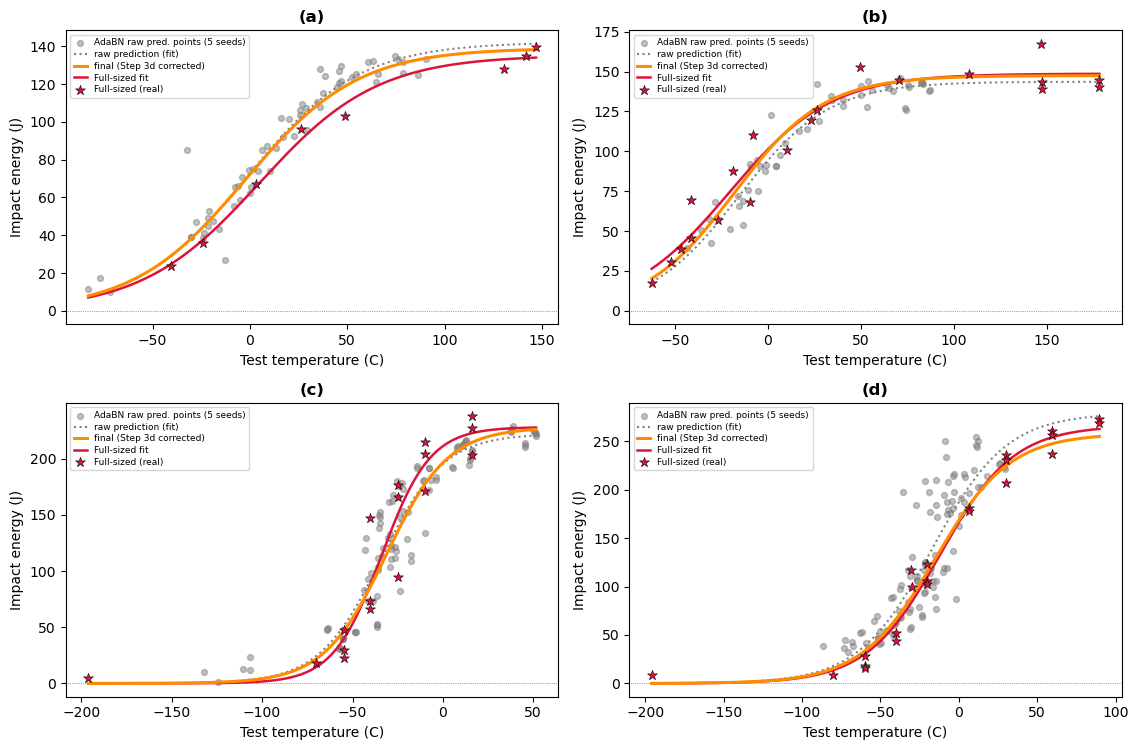

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
import string

_PAIR_CURVES = [273, 271, 233, 226]
n = len(_PAIR_CURVES)
ncols = 2
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(11.5, 3.8 * nrows))
axes = axes.ravel()

point_pred = pd.read_csv(ROOT / "Fig5_combined_point_predictions.csv")
final_res = pd.read_csv(ROOT / "Fig5_combined_corrected_final.csv").set_index("Curve")

for idx, sid in enumerate(_PAIR_CURVES):
    fid = SUB_TO_FULL_CURVE_MAP[sid]
    ax = axes[idx]

    g_full = full_raw[full_raw[CURVE_COL] == fid]
    t_full = pd.to_numeric(g_full[TCOL], errors="coerce").to_numpy(float)
    e_full = pd.to_numeric(g_full[ECOL], errors="coerce").to_numpy(float)
    mask = np.isfinite(t_full) & np.isfinite(e_full)
    t_full, e_full = t_full[mask], e_full[mask]
    full_params, _ = fit_tanh3_curve(t_full, e_full)

    pp = point_pred[point_pred.Curve == sid]
    t_pred, e_pred = pp.T_pred.to_numpy(float), pp.E_pred.to_numpy(float)
    raw_params, _ = fit_tanh3_curve(t_pred, e_pred)

    row = final_res.loc[sid]
    use_final, dbtt_final = row["USE_pred_final"], row["DBTT_pred_final"]
    k_shape = raw_params[2] if raw_params is not None else full_params[2]

    tg = np.linspace(min(t_pred.min(), t_full.min()), max(t_pred.max(), t_full.max()), 300)

    ax.scatter(t_pred, e_pred, s=18, color="gray", alpha=0.5, marker="o", zorder=2,
               label=f"AdaBN raw pred. points (5 seeds)")
    if raw_params is not None:
        ax.plot(tg, tanh3(tg, *raw_params), color="gray", lw=1.5, ls=":", zorder=2, label="raw prediction (fit)")

    ax.plot(tg, tanh3(tg, use_final, dbtt_final, k_shape), color="darkorange", lw=2.2, zorder=4,
            label="final (Step 3d corrected)")

    ax.plot(tg, tanh3(tg, *full_params), color="crimson", lw=1.8, zorder=3, label="Full-sized fit")
    ax.scatter(t_full, e_full, s=55, color="crimson", marker="*", edgecolor="black", linewidth=0.4,
               zorder=5, label="Full-sized (real)")

    ax.axhline(0, color="red", ls=":", lw=0.5)


    letter = string.ascii_lowercase[idx]
    ax.set_title(f"({letter})", fontsize=12, fontweight="bold", color="black")
    ax.set_xlabel("Test temperature (C)")
    ax.set_ylabel("Impact energy (J)")
    ax.legend(fontsize=6.5, loc="upper left", handlelength=1.4, labelspacing=0.3, borderpad=0.4)

for j in range(n, nrows * ncols):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig(ROOT / "Fig5_raw_vs_corrected_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()


## Table 4



In [10]:
table_df = pd.read_csv(ROOT / "GLplusEnvelope_11method_comparison_new.csv")
table_df = table_df[~table_df.method.isin(["Baseline", "RSD", "AdaBN"])].copy()
table_df = table_df.sort_values("USE_R2", ascending=False).reset_index(drop=True)
table_df.to_csv(ROOT / "Table_11method_comparison_final.csv", index=False)
table_df.drop(columns=["n_curves"])


,method,USE_R2,DBTT_R2
0,DANN,0.549151,0.680882
1,DAN-MMD,0.395059,0.787850
2,WDGRL,0.255348,0.642834
3,CMD,0.129767,0.820453
4,CDAN,0.040812,0.715983
5,SWD,-0.015718,0.802413
6,DeepCORAL,-0.093761,0.707670
7,ADDA,-2.271410,-0.132116


## Tables 6-7



In [11]:
ml_models = pd.DataFrame([
    ["XGBoost", 0.913, 0.963, 24.1, 0.814, 0.938, 27.2],
    ["LightGBM", 0.901, 0.965, 24.2, 0.892, 0.948, 17.8],
    ["Random Forest", 0.894, 0.961, 26.3, 0.776, 0.886, 29.2],
    ["GPR", 0.831, 0.914, 33.3, 0.786, 0.894, 28.6],
    ["Neural Networks", 0.837, 0.950, 32.7, 0.798, 0.896, 27.8],
    ["Gradient Boosting", 0.942, 0.974, 19.7, 0.830, 0.913, 27.0],
    ["CatBoost", 0.937, 0.970, 20.2, 0.838, 0.920, 24.9],
    ["Our method (final corrected)", 0.9569, 0.981, 18.84, 0.9628, 0.983, 12.02],
], columns=["Model", "USE_R2", "USE_r", "USE_RMSE", "DBTT_R2", "DBTT_r", "DBTT_RMSE"])
ml_models.to_csv(ROOT / "Table_vs_MLmodels_Yugandhar.csv", index=False)

analytical = pd.DataFrame([
    ["Lucas et al.", 0.723, 0.893, 42.2, None, None, None],
    ["Corwin et al.", 0.720, 0.902, 42.4, None, None, None],
    ["Louden et al.", -0.572, 0.805, 100.6, -4.944, 0.801, 148.4],
    ["Kayano et al.", 0.489, 0.888, 57.4, 0.493, 0.884, 43.3],
    ["Schubert et al.", -0.610, 0.753, 101.8, None, None, None],
    ["Uehira et al.", 0.488, 0.880, 57.4, 0.045, 0.337, 59.5],
    ["Uehira et al. (1)", 0.824, 0.939, 33.7, 0.498, 0.876, 43.1],
    ["Wallin et al.", 0.859, 0.944, 30.2, 0.584, 0.879, 39.3],
    ["Wallin et al. (2)", 0.802, 0.923, 35.7, None, None, None],
    ["Towers", None, None, None, 0.661, 0.899, 35.5],
    ["Sokolov et al.", None, None, None, 0.435, 0.881, 45.8],
    ["Lucon et al.", None, None, None, 0.485, 0.884, 43.7],
    ["Our method (final corrected)", 0.9569, 0.981, 18.84, 0.9628, 0.983, 12.02],
], columns=["Method", "USE_R2", "USE_r", "USE_RMSE", "DBTT_R2", "DBTT_r", "DBTT_RMSE"])
analytical.to_csv(ROOT / "Table_vs_analytical_Yugandhar.csv", index=False)

print("=== vs ML models ===")
display(ml_models)
print("=== vs classical analytical/empirical correlations ===")
display(analytical)


=== vs ML models ===


,Model,USE_R2,USE_r,USE_RMSE,DBTT_R2,DBTT_r,DBTT_RMSE
0,XGBoost,0.9130,0.963,24.10,0.8140,0.938,27.20
1,LightGBM,0.9010,0.965,24.20,0.8920,0.948,17.80
2,Random Forest,0.8940,0.961,26.30,0.7760,0.886,29.20
3,GPR,0.8310,0.914,33.30,0.7860,0.894,28.60
4,Neural Networks,0.8370,0.950,32.70,0.7980,0.896,27.80
5,Gradient Boosting,0.9420,0.974,19.70,0.8300,0.913,27.00
6,CatBoost,0.9370,0.970,20.20,0.8380,0.920,24.90
7,Our method (final corrected),0.9569,0.981,18.84,0.9628,0.983,12.02


=== vs classical analytical/empirical correlations ===


,Method,USE_R2,USE_r,USE_RMSE,DBTT_R2,DBTT_r,DBTT_RMSE
0,Lucas et al.,0.7230,0.893,42.20,NaN,NaN,NaN
1,Corwin et al.,0.7200,0.902,42.40,NaN,NaN,NaN
2,Louden et al.,-0.5720,0.805,100.60,-4.9440,0.801,148.40
3,Kayano et al.,0.4890,0.888,57.40,0.4930,0.884,43.30
4,Schubert et al.,-0.6100,0.753,101.80,NaN,NaN,NaN
5,Uehira et al.,0.4880,0.880,57.40,0.0450,0.337,59.50
6,Uehira et al. (1),0.8240,0.939,33.70,0.4980,0.876,43.10
7,Wallin et al.,0.8590,0.944,30.20,0.5840,0.879,39.30
8,Wallin et al. (2),0.8020,0.923,35.70,NaN,NaN,NaN
9,Towers,NaN,NaN,NaN,0.6610,0.899,35.50


## Ablation study

In [12]:
import time, json
mode = "combined"  # combined=n200 | gl_only | es_only | no_aug | n50 | n100 | n400 | n800
assert mode in ("combined", "gl_only", "es_only", "no_aug", "n50", "n100", "n200", "n400", "n800")

import warnings; warnings.filterwarnings("ignore")
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, least_squares, OptimizeWarning
from scipy.stats import truncnorm
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
warnings.filterwarnings("ignore", category=OptimizeWarning)

t_start = time.time()
ROOT = Path("/Users/wangtao/Downloads/files-6")
PREPROCESSED = ROOT / "Preprocessed_Data.xlsx"
TRANSFORMED = ROOT / "Transformed_Data.xlsx"
RAW_DATA = ROOT / "Charpy_Impact_Test_Dataset.xlsx"

TCOL, ECOL = "Test Temperature (C)", "Impact energy (J)"
TARGET_T, TARGET_E = "Transformed Temperature (°C)", "Transformed Absorbed Energy (J)"
CURVE_COL, REF_COL = "DBTT Fitted Curve", "Reference"
VALID_REFERENCES = [52, 53, 59]

SUB_TO_FULL_CURVE_MAP = {
    218: 216, 220: 216, 219: 217, 221: 217,
    226: 222, 230: 222, 234: 222, 242: 222,
    227: 223, 231: 223, 235: 223, 243: 223,
    228: 224, 232: 224, 236: 224, 244: 224,
    229: 225, 233: 225, 237: 225, 245: 225,
    270: 267, 272: 267, 273: 268, 294: 268,
    269: 266, 271: 266,
}
FULL_SIZE_GEOMETRY = {
    "Length (mm)": 55.0, "Width (mm)": 10.0, "Thickness (mm)": 10.0,
    "Notch Depth (mm)": 2.0, "Notch Angle (deg)": 45.0, "Notch Root Radius (mm)": 0.25,
}
FEATURE_COLS = [
    "C, wt.%", "Si, wt.%", "Mn, wt.%", "P, wt.%", "S, wt.%", "Ni, wt.%",
    "Cr, wt.%", "Mo, wt.%", "Fe, wt.%", "Cu, wt.%", "V, wt.%",
    "Manufacturer", "Treatment", "Post Treatment Temperature (ºC)",
    "Post Treatment Time (h)", "Cooling", "Microstructure", "Grain size (um)",
    "Irradiated Specimen", "Irradiation Dose (n/cm^2)", "Irradiation Temperature (ºC)",
    "Length (mm)", "Width (mm)", "Thickness (mm)", "Notch Depth (mm)",
    "Notch Angle (deg)", "Notch Root Radius (mm)", "Notch Shape",
    "Test Standard", TCOL, "Orientation", "Test Condition Statement",
]
GEOMETRY_COLS = ["Length (mm)", "Width (mm)", "Thickness (mm)",
                  "Notch Depth (mm)", "Notch Angle (deg)", "Notch Root Radius (mm)"]
CV_FOLDS = {
    "fold_1": [218.0, 226.0, 233.0, 269.0, 272.0],
    "fold_2": [220.0, 227.0, 234.0, 231.0, 270.0],
    "fold_3": [219.0, 228.0, 232.0, 237.0, 294.0],
    "fold_4": [221.0, 229.0, 236.0, 230.0, 245.0],
    "fold_5": [242.0, 235.0, 244.0, 273.0, 271.0, 243.0],
}


def load_merged_subsize_data():
    df_all = pd.read_excel(PREPROCESSED, header=0)
    df_transformed = pd.read_excel(TRANSFORMED, header=0)
    key = [REF_COL, CURVE_COL, TCOL]
    left = df_all.copy()
    right = df_transformed[key + [TARGET_T, TARGET_E]].copy()
    for c in [REF_COL, CURVE_COL]:
        left[c] = pd.to_numeric(left[c], errors="coerce")
        right[c] = pd.to_numeric(right[c], errors="coerce")
    left[TCOL] = pd.to_numeric(left[TCOL], errors="coerce")
    right[TCOL] = pd.to_numeric(right[TCOL], errors="coerce")
    right = right.sort_values(key).drop_duplicates(subset=key, keep="first")
    df = left.merge(right, on=key, how="left", validate="many_to_one")
    assert len(df) == len(df_all)
    df = df.astype("float64")
    return df[df[REF_COL].isin(VALID_REFERENCES)].reset_index(drop=True)


def load_raw_fullsize_data():
    full_df = pd.read_excel(RAW_DATA, header=1)
    full_df.columns = full_df.columns.str.strip()
    full_df = full_df[full_df[REF_COL].isin(VALID_REFERENCES)]
    full_df = full_df[full_df["Width (mm)"] == 10].copy()
    full_df[TCOL] = pd.to_numeric(full_df[TCOL], errors="coerce")
    full_df[ECOL] = pd.to_numeric(full_df[ECOL], errors="coerce")
    return full_df.reset_index(drop=True)


def tanh3(temp, use, dbtt, k):
    return 0.5 * use * (1.0 + np.tanh((temp - dbtt) / k))


def fit_tanh3_curve(temp, energy, min_points=4):
    temp = pd.to_numeric(pd.Series(temp), errors="coerce").to_numpy(float)
    energy = pd.to_numeric(pd.Series(energy), errors="coerce").to_numpy(float)
    mask = np.isfinite(temp) & np.isfinite(energy)
    temp, energy = temp[mask], energy[mask]
    if len(temp) < min_points or np.nanmax(temp) - np.nanmin(temp) < 5:
        return None, None
    order = np.argsort(temp)
    temp, energy = temp[order], energy[order]
    use0 = max(float(np.nanmax(energy)), 1.0)
    dbtt0 = float(temp[np.nanargmin(np.abs(energy - np.nanmedian(energy)))])
    k0 = max(float((np.nanmax(temp) - np.nanmin(temp)) / 6.0), 5.0)
    try:
        params, _ = curve_fit(tanh3, temp, energy, p0=[use0, dbtt0, k0],
                               bounds=([0.2, np.nanmin(temp) - 300.0, 1.0],
                                       [max(3.0 * use0, 10.0), np.nanmax(temp) + 300.0, 500.0]),
                               maxfev=30000)
        return params, energy - tanh3(temp, *params)
    except Exception:
        return None, None


def tanh_fn(x, a, b, c, d):
    return a * np.tanh(b * (x - c)) + d


def fit_tanh_bounded(x, y):
    df_xy = pd.DataFrame({"x": x, "y": y}).groupby("x", as_index=False)["y"].mean()
    x = df_xy["x"].to_numpy(float); y = df_xy["y"].to_numpy(float)
    if len(x) < 4 or np.nanstd(y) < 1e-6:
        raise RuntimeError("not enough variation")
    scaler = StandardScaler()
    xs = scaler.fit_transform(x.reshape(-1, 1)).ravel()
    y_min, y_max = float(y.min()), float(y.max())
    y_span = max(y_max - y_min, 1.0)
    lb = np.array([0.0, 1e-3, xs.min() - 0.5, y_min - 0.5 * y_span])
    ub = np.array([max(2.0 * y_span, 20.0), 10.0, xs.max() + 0.5, y_max + 0.5 * y_span])
    p0 = np.array([0.5 * y_span, 1.0, float(np.median(xs)), float(np.mean(y))])

    def resid_fn(p):
        return tanh_fn(xs, *p) - y

    res = least_squares(resid_fn, p0, bounds=(lb, ub), loss="soft_l1", f_scale=1.0, max_nfev=20000)
    if not res.success:
        raise RuntimeError("fit did not converge")
    return res.x, scaler


def dbtt_use_from_params(params, scaler):
    a, b, c, d = params
    use = a + d
    dbtt = scaler.inverse_transform([[c]])[0, 0]
    return float(use), float(dbtt)


def yugandhar_transform(temp_sub, energy_sub, sub_params, full_params):
    use_sub, dbtt_sub, _k_sub = sub_params
    use_full, dbtt_full, k_full = full_params
    temp_sub = np.asarray(temp_sub, dtype=float)
    energy_sub = np.asarray(energy_sub, dtype=float)
    shift = dbtt_full - dbtt_sub
    temp_transformed = temp_sub + shift
    residual = energy_sub - tanh3(temp_sub, *sub_params)
    scaled_residual = residual * (use_full / max(use_sub, 1e-6))
    energy_transformed = tanh3(temp_transformed, *full_params) + scaled_residual
    return temp_transformed, energy_transformed


def fit_full_curve_params(full_raw_df, full_curve_id):
    sub = full_raw_df[full_raw_df[CURVE_COL] == full_curve_id]
    return fit_tanh3_curve(sub[TCOL], sub[ECOL])


df = load_merged_subsize_data()
full_raw = load_raw_fullsize_data()
print("Loaded sub-sized and full-sized curves successfully.", flush=True)

# ============================================================ Step 1: sampling (mode-dependent N)
FLOOR = 1e-6
GRID = 600
N_BY_MODE = {"n50": 50, "n100": 100, "n200": 200, "n400": 400, "n800": 800}
N_SYNTHETIC = N_BY_MODE.get(mode, 200)
GL_RNG_SEED = 20260826
ENVELOPE_RNG_SEED = 20262826


def _kernel_w(a, b, h):
    d = (a[:, None] - b[None, :]) / h
    return np.exp(-0.5 * d ** 2)


def sigma_at(tq, t_obs, resid, h):
    tq = np.atleast_1d(tq)
    w = _kernel_w(tq, t_obs, h)
    num = (w * resid[None, :] ** 2).sum(1)
    den = np.maximum(w.sum(1), FLOOR)
    return np.sqrt(num / den)


def mean_at(tq, t_obs, resid, h):
    tq = np.atleast_1d(tq)
    w = _kernel_w(tq, t_obs, h)
    return (w * resid[None, :]).sum(1) / np.maximum(w.sum(1), FLOOR)


def _loo_log_lik(h, t_obs, resid):
    n = len(t_obs); total = 0.0; idx = np.arange(n)
    for i in range(n):
        mask = idx != i
        s = sigma_at(t_obs[i:i + 1], t_obs[mask], resid[mask], h)[0]
        s = max(s, FLOOR)
        total += -0.5 * np.log(2 * np.pi * s ** 2) - resid[i] ** 2 / (2 * s ** 2)
    return total


def select_bandwidth(t_obs, resid, n_grid=50):
    t_sorted = np.sort(np.unique(t_obs))
    gaps = np.diff(t_sorted); gaps = gaps[gaps > 1e-9]
    hi = t_obs.max() - t_obs.min()
    lo = gaps.min() if len(gaps) else hi
    lo = min(lo, 0.5 * hi) if hi > 0 else 1.0
    grid = np.geomspace(max(lo, 1e-6), max(hi, lo * 2), n_grid)
    scores = [_loo_log_lik(h, t_obs, resid) for h in grid]
    return float(grid[int(np.argmax(scores))])


def positions_rule_sigma(t_obs, resid, n, rng, h, grid=GRID):
    tg = np.linspace(t_obs.min(), t_obs.max(), grid)
    w = sigma_at(tg, t_obs, resid, h)
    w = np.maximum(w, FLOOR)
    idx = rng.choice(grid, size=n, p=w / w.sum())
    step = tg[1] - tg[0]
    return np.clip(tg[idx] + rng.uniform(-step / 2, step / 2, n), t_obs.min(), t_obs.max())


def gaussian_local_sample(t_obs, resid, params, n, rng, h):
    T = positions_rule_sigma(t_obs, resid, n, rng, h)
    mu = tanh3(T, *params) + mean_at(T, t_obs, resid, h)
    sig = np.maximum(sigma_at(T, t_obs, resid, h), FLOOR)
    E = rng.normal(mu, sig)
    return T, E


def envelope(tg, t_obs, resid, h):
    tg = np.atleast_1d(tg)
    w = _kernel_w(tg, t_obs, h)
    pos = np.where(resid > 0, resid, 0.0)
    neg = np.where(resid < 0, resid, 0.0)
    up = (w * pos[None, :]).max(1)
    lo = (w * neg[None, :]).min(1)
    return lo, up


def positions_rule_c(t_obs, resid, n, rng, h, grid=GRID):
    tg = np.linspace(t_obs.min(), t_obs.max(), grid)
    lo, up = envelope(tg, t_obs, resid, h)
    w = np.maximum(up - lo, 0.0)
    if w.sum() <= 0:
        w = np.ones_like(tg)
    idx = rng.choice(grid, size=n, p=w / w.sum())
    step = tg[1] - tg[0]
    return np.clip(tg[idx] + rng.uniform(-step / 2, step / 2, n), t_obs.min(), t_obs.max())


def envelope_sample(t_obs, resid, params, n, rng, h):
    T = positions_rule_c(t_obs, resid, n, rng, h)
    lo, up = envelope(T, t_obs, resid, h)
    E = tanh3(T, *params) + lo + rng.random(n) * (up - lo)
    return T, E


use_gl = mode != "es_only"
use_envelope = mode != "gl_only"

gl_rows, envelope_rows = [], []
curve_fit_info = {}
for i, cid in enumerate(sorted(df[CURVE_COL].unique())):
    g = df[df[CURVE_COL] == cid].reset_index(drop=True)
    fit_params, _ = fit_tanh3_curve(g[TCOL], g[ECOL])
    if fit_params is None:
        continue
    t_obs = pd.to_numeric(g[TCOL], errors="coerce").to_numpy(float)
    e_obs = pd.to_numeric(g[ECOL], errors="coerce").to_numpy(float)
    mask = np.isfinite(t_obs) & np.isfinite(e_obs)
    t_obs, e_obs = t_obs[mask], e_obs[mask]
    order = np.argsort(t_obs)
    t_obs, e_obs = t_obs[order], e_obs[order]
    resid = e_obs - tanh3(t_obs, *fit_params)
    h = select_bandwidth(t_obs, resid)
    curve_fit_info[int(cid)] = dict(params=fit_params, t_obs=t_obs, resid=resid, h=h)

    base_row = g.iloc[0].copy()

    if use_gl:
        rng_gl = np.random.default_rng(GL_RNG_SEED + 100 * i)
        T_gl, E_gl = gaussian_local_sample(t_obs, resid, fit_params, N_SYNTHETIC, rng_gl, h)
        rows_gl = pd.concat([base_row.to_frame().T] * N_SYNTHETIC, ignore_index=True)
        rows_gl[TCOL] = T_gl; rows_gl[ECOL] = E_gl; rows_gl["Synthetic"] = True
        rows_gl["Sub_USE_fit"] = fit_params[0]; rows_gl["Sub_DBTT_fit"] = fit_params[1]; rows_gl["Sub_k_fit"] = fit_params[2]
        gl_rows.append(rows_gl)

    if use_envelope:
        rng_envelope = np.random.default_rng(ENVELOPE_RNG_SEED + 100 * i)
        T_envelope, E_envelope = envelope_sample(t_obs, resid, fit_params, N_SYNTHETIC, rng_envelope, h)
        rows_envelope = pd.concat([base_row.to_frame().T] * N_SYNTHETIC, ignore_index=True)
        rows_envelope[TCOL] = T_envelope; rows_envelope[ECOL] = E_envelope; rows_envelope["Synthetic"] = True
        rows_envelope["Sub_USE_fit"] = fit_params[0]; rows_envelope["Sub_DBTT_fit"] = fit_params[1]; rows_envelope["Sub_k_fit"] = fit_params[2]
        envelope_rows.append(rows_envelope)

parts = []
if use_gl: parts.append(pd.concat(gl_rows, ignore_index=True))
if use_envelope: parts.append(pd.concat(envelope_rows, ignore_index=True))
synthetic = pd.concat(parts, ignore_index=True)
print(f"Step 1 ({mode}): synthetic points generated (GL={use_gl}, Envelope Sampling={use_envelope}).  [{time.time()-t_start:.0f}s]", flush=True)

# ============================================================ Step 2: Yugandhar transform
curve_params = {}
for cid, g in df.groupby(CURVE_COL):
    sub_params, _ = fit_tanh3_curve(g[TCOL], g[ECOL])
    full_cid = SUB_TO_FULL_CURVE_MAP.get(int(cid))
    if sub_params is None or full_cid is None:
        continue
    full_params, _ = fit_full_curve_params(full_raw, full_cid)
    if full_params is None:
        continue
    curve_params[int(cid)] = (sub_params, full_cid, full_params)

real_target_rows = []
for cid, g in df.groupby(CURVE_COL):
    cid = int(cid)
    if cid not in curve_params:
        continue
    sub_params, full_cid, full_params = curve_params[cid]
    rows = g.copy()
    rows["Origin_T_sub"] = g[TCOL]; rows["Origin_E_sub"] = g[ECOL]
    rows["Sub_USE_fit"] = sub_params[0]; rows["Sub_DBTT_fit"] = sub_params[1]; rows["Sub_k_fit"] = sub_params[2]
    rows[TCOL] = g[TARGET_T]; rows[ECOL] = g[TARGET_E]
    for col, val in FULL_SIZE_GEOMETRY.items():
        rows[col] = val
    rows["Synthetic"] = False; rows["Full_Curve"] = full_cid
    real_target_rows.append(rows)
real_target_df = pd.concat(real_target_rows, ignore_index=True)

synth_out_parts = []
for cid, g in synthetic.groupby(CURVE_COL):
    cid = int(cid)
    if cid not in curve_params:
        continue
    sub_params, full_cid, full_params = curve_params[cid]
    t_t, e_t = yugandhar_transform(g[TCOL].to_numpy(float), g[ECOL].to_numpy(float), sub_params, full_params)
    rows = g.copy()
    rows["Origin_T_sub"] = g[TCOL]; rows["Origin_E_sub"] = g[ECOL]
    rows[TCOL] = t_t; rows[ECOL] = e_t
    for col, val in FULL_SIZE_GEOMETRY.items():
        rows[col] = val
    rows["Synthetic"] = True; rows["Full_Curve"] = full_cid
    synth_out_parts.append(rows)
synth_target_df = pd.concat(synth_out_parts, ignore_index=True)
print(f"Step 2 ({mode}): synthetic points transformed successfully.  [{time.time()-t_start:.0f}s]", flush=True)

# ============================================================ Step 3a: assembly + RealAug
INPUT_COLS = FEATURE_COLS + [ECOL]
OUTPUT_COLS = [TARGET_T, TARGET_E]
K_AUG = 0 if mode == "no_aug" else 4
ENERGY_SCALE_FRAC = 0.4
TEMP_JITTER_STD = 0.5


def make_rows(frame):
    out = frame.copy()
    out[TARGET_T] = frame[TCOL]; out[TARGET_E] = frame[ECOL]
    out[TCOL] = frame["Origin_T_sub"]; out[ECOL] = frame["Origin_E_sub"]
    geom_by_curve = df.groupby(CURVE_COL)[GEOMETRY_COLS].first()
    geom = geom_by_curve.loc[frame[CURVE_COL].to_numpy()].reset_index(drop=True)
    for col in GEOMETRY_COLS:
        out[col] = geom[col].to_numpy()
    cols = FEATURE_COLS + [ECOL, TARGET_T, TARGET_E, CURVE_COL]
    return out[cols]


source_df = make_rows(synth_target_df)
target_df = make_rows(real_target_df)

full_use_dbtt = (full_raw[[CURVE_COL, "USE (J)", "DBTT (ºC)"]]
                 .drop_duplicates(subset=[CURVE_COL]).set_index(CURVE_COL))
curve_info = {}
for cid, (sub_params, full_cid, full_params) in curve_params.items():
    curve_info[cid] = {"sub_params": sub_params, "full_curve": full_cid}


def augment_target(tgt_train, curve_fit_info, rng):
    rows = [tgt_train]
    for _ in range(K_AUG):
        g = tgt_train.copy()
        t_sub = g[TCOL].to_numpy(float); e_sub = g[ECOL].to_numpy(float)
        cids = g[CURVE_COL].to_numpy(int)
        sigma = np.empty(len(g)); use_arr = np.empty(len(g))
        for c in np.unique(cids):
            m = cids == c
            info = curve_fit_info[c]
            sigma[m] = sigma_at(t_sub[m], info["t_obs"], info["resid"], info["h"])
            use_arr[m] = info["params"][0]
        sigma = np.maximum(sigma * ENERGY_SCALE_FRAC, 1e-6)
        lower = np.maximum(-2.5 * sigma, -e_sub)
        upper = np.minimum(2.5 * sigma, 1.3 * use_arr - e_sub)
        bad = lower >= upper
        lower[bad] = -1e-9; upper[bad] = 1e-9
        a, b = lower / sigma, upper / sigma
        e_noise = truncnorm.rvs(a, b, loc=0.0, scale=sigma, random_state=rng)
        g[ECOL] = e_sub + e_noise
        g[TCOL] = t_sub + rng.normal(0.0, TEMP_JITTER_STD, size=len(g))
        rows.append(g)
    return pd.concat(rows, ignore_index=True)


def build_test_rows(test_curve_ids, df):
    rows_per_curve = {}
    for cid in test_curve_ids:
        cid = int(cid)
        g = df[df[CURVE_COL] == cid]
        if len(g) < 3:
            continue
        rows_per_curve[cid] = {"X": g[FEATURE_COLS + [ECOL]].astype(float).reset_index(drop=True)}
    return rows_per_curve


print(f"Step 3a ({mode}): source/target pools assembled, K_AUG={K_AUG}.  [{time.time()-t_start:.0f}s]", flush=True)

# ============================================================ Step 3b: all methods
DEVICE = "cpu"; EPOCHS = 300; BATCH = 128; LR = 1e-3; WEIGHT_DECAY = 1e-3
DROPOUT = 0.3; HIDDEN = 32; LATENT = 16
LAMBDA_MAX = 1.0; LAMBDA_METHOD_OVERRIDES = {"DANN": 0.3}
ALL_METHODS = ["Baseline", "DANN", "DeepCORAL", "DAN-MMD", "WDGRL",
               "CDAN", "CMD", "AdaBN", "SWD", "ADDA", "RSD"]


class Encoder(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, HIDDEN), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN, LATENT), nn.ReLU())

    def forward(self, x):
        return self.net(x)


class RegressionHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LATENT, 16), nn.ReLU(), nn.Linear(16, 2))

    def forward(self, z):
        return self.net(z)


class DomainDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LATENT, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, z):
        return self.net(z).squeeze(-1)


class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lambd):
        ctx.lambd = lambd
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambd * grad_output, None


def grad_reverse(x, lambd):
    return GradReverse.apply(x, lambd)


def coral_loss(zs, zt):
    d = zs.shape[1]
    zs_c = zs - zs.mean(0, keepdim=True)
    zt_c = zt - zt.mean(0, keepdim=True)
    cs = (zs_c.T @ zs_c) / (zs.shape[0] - 1)
    ct = (zt_c.T @ zt_c) / (zt.shape[0] - 1)
    return ((cs - ct) ** 2).sum() / (4 * d * d)


def mmd_loss(zs, zt, kernel_muls=(0.5, 1.0, 2.0, 4.0, 8.0)):
    z = torch.cat([zs, zt], 0)
    dist = torch.cdist(z, z, p=2) ** 2
    bandwidth = torch.median(dist[dist > 0]).detach()
    bandwidth = torch.clamp(bandwidth, min=1e-6)
    kernels = sum(torch.exp(-dist / (bandwidth * m)) for m in kernel_muls)
    ns = zs.shape[0]
    kxx = kernels[:ns, :ns].mean(); kyy = kernels[ns:, ns:].mean(); kxy = kernels[:ns, ns:].mean()
    return kxx + kyy - 2 * kxy


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LATENT, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, z):
        return self.net(z).squeeze(-1)


def gradient_penalty(critic, zs, zt):
    n = min(len(zs), len(zt))
    alpha = torch.rand(n, 1)
    interp = (alpha * zs[:n] + (1 - alpha) * zt[:n]).requires_grad_(True)
    out = critic(interp)
    grads = torch.autograd.grad(out.sum(), interp, create_graph=True)[0]
    return ((grads.norm(2, dim=1) - 1) ** 2).mean()


def iterate_batches(n, batch_size, rng):
    idx = rng.permutation(n)
    for i in range(0, n, batch_size):
        yield idx[i:i + batch_size]


def train_model(method, Xs, ys, Xt, yt, in_dim, epochs=EPOCHS, seed=0):
    rng = np.random.default_rng(seed)
    enc = Encoder(in_dim); head = RegressionHead()
    params = list(enc.parameters()) + list(head.parameters())
    disc = critic = None
    if method == "DANN":
        disc = DomainDiscriminator(); params += list(disc.parameters())
    if method == "WDGRL":
        critic = Critic()
    opt = torch.optim.Adam(params, lr=LR, weight_decay=WEIGHT_DECAY)
    opt_critic = torch.optim.Adam(critic.parameters(), lr=LR) if critic else None
    mse = nn.MSELoss(); bce = nn.BCEWithLogitsLoss()
    n = min(len(Xs), len(Xt))
    for epoch in range(epochs):
        p = epoch / epochs
        lam_max = LAMBDA_METHOD_OVERRIDES.get(method, LAMBDA_MAX)
        lam = lam_max * (2.0 / (1.0 + np.exp(-8 * p)) - 1.0)
        for bidx in iterate_batches(n, BATCH, rng):
            si = rng.choice(len(Xs), size=len(bidx), replace=len(Xs) < len(bidx))
            ti = rng.choice(len(Xt), size=len(bidx), replace=len(Xt) < len(bidx))
            xs = torch.tensor(Xs[si], dtype=torch.float32); ysb = torch.tensor(ys[si], dtype=torch.float32)
            xt = torch.tensor(Xt[ti], dtype=torch.float32); ytb = torch.tensor(yt[ti], dtype=torch.float32)
            if method == "WDGRL":
                with torch.no_grad():
                    zs_fixed = enc(xs); zt_fixed = enc(xt)
                for _ in range(3):
                    opt_critic.zero_grad()
                    loss_c = -(critic(zs_fixed).mean() - critic(zt_fixed).mean())
                    gp = gradient_penalty(critic, zs_fixed, zt_fixed)
                    (loss_c + 10.0 * gp).backward()
                    torch.nn.utils.clip_grad_norm_(critic.parameters(), max_norm=5.0)
                    opt_critic.step()
            opt.zero_grad()
            zs = enc(xs); zt = enc(xt)
            pred_s = head(zs); pred_t = head(zt)
            task_loss = mse(pred_s, ysb) + mse(pred_t, ytb)
            if method == "Baseline":
                loss = task_loss
            elif method == "DANN":
                dom_s = disc(grad_reverse(zs, lam)); dom_t = disc(grad_reverse(zt, lam))
                dom_loss = bce(dom_s, torch.zeros_like(dom_s)) + bce(dom_t, torch.ones_like(dom_t))
                loss = task_loss + dom_loss
            elif method == "DeepCORAL":
                loss = task_loss + lam * coral_loss(zs, zt)
            elif method == "DAN-MMD":
                loss = task_loss + lam * mmd_loss(zs, zt)
            elif method == "WDGRL":
                wd = critic(zs).mean() - critic(zt).mean()
                loss = task_loss + lam * wd
            else:
                raise ValueError(method)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, max_norm=5.0)
            opt.step()
    enc.eval(); head.eval()
    return enc, head


def predict(enc, head, X):
    with torch.no_grad():
        z = enc(torch.tensor(X, dtype=torch.float32))
        return np.array(head(z).detach().tolist())


def cmd_loss(zs, zt, n_moments=4):
    mu_s, mu_t = zs.mean(0), zt.mean(0)
    loss = torch.norm(mu_s - mu_t, p=2)
    zs_c, zt_c = zs - mu_s, zt - mu_t
    for k in range(2, n_moments + 1):
        loss = loss + torch.norm((zs_c ** k).mean(0) - (zt_c ** k).mean(0), p=2)
    return loss / n_moments


def sliced_wasserstein_loss(zs, zt, n_proj=50):
    d = zs.shape[1]
    proj = torch.randn(d, n_proj)
    proj = proj / proj.norm(dim=0, keepdim=True)
    zs_p, zt_p = zs @ proj, zt @ proj
    zs_sorted, _ = torch.sort(zs_p, dim=0)
    zt_sorted, _ = torch.sort(zt_p, dim=0)
    n = min(zs_sorted.shape[0], zt_sorted.shape[0])
    return ((zs_sorted[:n] - zt_sorted[:n]) ** 2).mean()


def rsd_loss(zs, zt, k=8):
    zs_c = (zs - zs.mean(0, keepdim=True)).double()
    zt_c = (zt - zt.mean(0, keepdim=True)).double()
    zs_c = zs_c + 1e-4 * torch.randn_like(zs_c)
    zt_c = zt_c + 1e-4 * torch.randn_like(zt_c)
    k = min(k, zs_c.shape[0] - 1, zt_c.shape[0] - 1, zs_c.shape[1])
    try:
        Us, _, _ = torch.linalg.svd(zs_c, full_matrices=False)
        Ut, _, _ = torch.linalg.svd(zt_c, full_matrices=False)
    except Exception:
        return torch.tensor(0.0, dtype=zs.dtype)
    M = Us[:, :k].T @ Ut[:, :k]
    _, sing, _ = torch.linalg.svd(M)
    sing = torch.clamp(sing, -1.0, 1.0)
    return (torch.acos(sing) ** 2).sum().float()


class CondDomainDiscriminator(nn.Module):
    def __init__(self, latent_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(latent_dim + out_dim, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, z, pred):
        return self.net(torch.cat([z, pred], dim=1)).squeeze(-1)


class BNEncoder(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, HIDDEN)
        self.bn1_src = nn.BatchNorm1d(HIDDEN); self.bn1_tgt = nn.BatchNorm1d(HIDDEN)
        self.fc2 = nn.Linear(HIDDEN, LATENT)
        self.bn2_src = nn.BatchNorm1d(LATENT); self.bn2_tgt = nn.BatchNorm1d(LATENT)
        self.relu = nn.ReLU(); self.drop = nn.Dropout(DROPOUT)

    def forward(self, x, domain):
        bn1 = self.bn1_src if domain == "source" else self.bn1_tgt
        bn2 = self.bn2_src if domain == "source" else self.bn2_tgt
        h = self.drop(self.relu(bn1(self.fc1(x))))
        return self.relu(bn2(self.fc2(h)))


def train_generic(method, Xs, ys, Xt, yt, in_dim, epochs=EPOCHS, seed=0):
    rng = np.random.default_rng(seed)
    enc = Encoder(in_dim); head = RegressionHead()
    params = list(enc.parameters()) + list(head.parameters())
    disc = None
    if method == "CDAN":
        disc = CondDomainDiscriminator(LATENT, 2); params += list(disc.parameters())
    opt = torch.optim.Adam(params, lr=LR, weight_decay=WEIGHT_DECAY)
    mse = nn.MSELoss(); bce = nn.BCEWithLogitsLoss()
    n = min(len(Xs), len(Xt))
    for epoch in range(epochs):
        p = epoch / epochs
        lam = LAMBDA_MAX * (2.0 / (1.0 + np.exp(-8 * p)) - 1.0)
        for bidx in iterate_batches(n, BATCH, rng):
            si = rng.choice(len(Xs), size=len(bidx), replace=len(Xs) < len(bidx))
            ti = rng.choice(len(Xt), size=len(bidx), replace=len(Xt) < len(bidx))
            xs = torch.tensor(Xs[si], dtype=torch.float32); ysb = torch.tensor(ys[si], dtype=torch.float32)
            xt = torch.tensor(Xt[ti], dtype=torch.float32); ytb = torch.tensor(yt[ti], dtype=torch.float32)
            opt.zero_grad()
            zs, zt = enc(xs), enc(xt)
            pred_s, pred_t = head(zs), head(zt)
            task_loss = mse(pred_s, ysb) + mse(pred_t, ytb)
            if method == "CDAN":
                dom_s = disc(grad_reverse(zs, lam), pred_s.detach())
                dom_t = disc(grad_reverse(zt, lam), pred_t.detach())
                dom_loss = bce(dom_s, torch.zeros_like(dom_s)) + bce(dom_t, torch.ones_like(dom_t))
                loss = task_loss + dom_loss
            elif method == "CMD":
                loss = task_loss + lam * cmd_loss(zs, zt)
            elif method == "SWD":
                loss = task_loss + lam * sliced_wasserstein_loss(zs, zt)
            elif method == "RSD":
                loss = task_loss + lam * rsd_loss(zs, zt)
            else:
                raise ValueError(method)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, max_norm=5.0)
            opt.step()
    enc.eval(); head.eval()
    return enc, head


def train_adabn(Xs, ys, Xt, yt, in_dim, epochs=EPOCHS, seed=0):
    rng = np.random.default_rng(seed)
    enc = BNEncoder(in_dim); head = RegressionHead()
    params = list(enc.parameters()) + list(head.parameters())
    opt = torch.optim.Adam(params, lr=LR, weight_decay=WEIGHT_DECAY)
    mse = nn.MSELoss()
    n = min(len(Xs), len(Xt))
    for epoch in range(epochs):
        for bidx in iterate_batches(n, BATCH, rng):
            si = rng.choice(len(Xs), size=len(bidx), replace=len(Xs) < len(bidx))
            ti = rng.choice(len(Xt), size=len(bidx), replace=len(Xt) < len(bidx))
            xs = torch.tensor(Xs[si], dtype=torch.float32); ysb = torch.tensor(ys[si], dtype=torch.float32)
            xt = torch.tensor(Xt[ti], dtype=torch.float32); ytb = torch.tensor(yt[ti], dtype=torch.float32)
            opt.zero_grad()
            pred_s = head(enc(xs, "source")); pred_t = head(enc(xt, "target"))
            loss = mse(pred_s, ysb) + mse(pred_t, ytb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, max_norm=5.0)
            opt.step()
    enc.eval(); head.eval()
    return enc, head


def train_adda(Xs, ys, Xt, yt, in_dim, epochs=EPOCHS, seed=0, pretrain_epochs=150):
    rng = np.random.default_rng(seed)
    src_enc = Encoder(in_dim); head = RegressionHead()
    opt1 = torch.optim.Adam(list(src_enc.parameters()) + list(head.parameters()), lr=LR, weight_decay=WEIGHT_DECAY)
    mse = nn.MSELoss()
    for epoch in range(pretrain_epochs):
        for bidx in iterate_batches(len(Xs), BATCH, rng):
            xs = torch.tensor(Xs[bidx], dtype=torch.float32); ysb = torch.tensor(ys[bidx], dtype=torch.float32)
            opt1.zero_grad()
            loss = mse(head(src_enc(xs)), ysb)
            loss.backward(); opt1.step()
    src_enc.eval()
    for p in src_enc.parameters(): p.requires_grad_(False)
    for p in head.parameters(): p.requires_grad_(False)
    tgt_enc = Encoder(in_dim); tgt_enc.load_state_dict(src_enc.state_dict())
    disc = DomainDiscriminator()
    opt2 = torch.optim.Adam(tgt_enc.parameters(), lr=LR)
    opt_disc = torch.optim.Adam(disc.parameters(), lr=LR)
    bce = nn.BCEWithLogitsLoss()
    n = min(len(Xs), len(Xt))
    for epoch in range(epochs):
        for bidx in iterate_batches(n, BATCH, rng):
            si = rng.choice(len(Xs), size=len(bidx), replace=len(Xs) < len(bidx))
            ti = rng.choice(len(Xt), size=len(bidx), replace=len(Xt) < len(bidx))
            xs = torch.tensor(Xs[si], dtype=torch.float32); xt = torch.tensor(Xt[ti], dtype=torch.float32)
            with torch.no_grad():
                zs = src_enc(xs)
            zt = tgt_enc(xt)
            opt_disc.zero_grad()
            d_s = disc(zs.detach()); d_t = disc(zt.detach())
            loss_d = bce(d_s, torch.zeros_like(d_s)) + bce(d_t, torch.ones_like(d_t))
            loss_d.backward(); opt_disc.step()
            opt2.zero_grad()
            zt = tgt_enc(xt); d_t = disc(zt)
            loss_g = bce(d_t, torch.zeros_like(d_t))
            loss_g.backward()
            torch.nn.utils.clip_grad_norm_(tgt_enc.parameters(), max_norm=5.0)
            opt2.step()
    tgt_enc.eval()
    for p in head.parameters(): p.requires_grad_(True)
    return tgt_enc, head


def predict_domain_aware(enc, head, X, method, domain):
    with torch.no_grad():
        xt = torch.tensor(X, dtype=torch.float32)
        z = enc(xt, domain) if method == "AdaBN" else enc(xt)
        return np.array(head(z).detach().tolist())


def train_method(method, Xs, ys, Xt, yt, in_dim, seed):
    if method in ("Baseline", "DANN", "DeepCORAL", "DAN-MMD", "WDGRL"):
        return train_model(method, Xs, ys, Xt, yt, in_dim=in_dim, seed=seed)
    if method == "AdaBN":
        return train_adabn(Xs, ys, Xt, yt, in_dim=in_dim, seed=seed)
    if method == "ADDA":
        return train_adda(Xs, ys, Xt, yt, in_dim=in_dim, seed=seed)
    return train_generic(method, Xs, ys, Xt, yt, in_dim=in_dim, seed=seed)


def predict_method(method, enc, head, Xte):
    if method in ("Baseline", "DANN", "DeepCORAL", "DAN-MMD", "WDGRL"):
        return predict(enc, head, Xte)
    return predict_domain_aware(enc, head, Xte, method, "target")


print(f"Step 3b: DA methods defined.  [{time.time()-t_start:.0f}s]")



# ============================================================ Step 3c: Finetuning
USE_CONFIG_BY_CURVE = {218: (32, 16, 0.5), 219: (32, 8, 0.3), 220: (32, 16, 0.1), 221: (32, 16, 0.1), 226: (32, 16, 0.3), 227: (32, 32, 0.3), 228: (32, 16, 0.3), 229: (32, 16, 0.5), 230: (32, 16, 0.1), 231: (32, 16, 0.5), 232: (32, 16, 0.3), 233: (64, 16, 0.3), 234: (32, 16, 0.1), 235: (32, 16, 0.5), 236: (32, 16, 0.1), 237: (32, 16, 0.1), 242: (64, 16, 0.3), 243: (32, 32, 0.3), 244: (32, 32, 0.3), 245: (32, 16, 0.3), 269: (32, 16, 0.1), 270: (32, 8, 0.3), 271: (16, 16, 0.3), 272: (32, 8, 0.3), 273: (32, 32, 0.3), 294: (32, 16, 0.5)}
DBTT_CONFIG_BY_CURVE = {218: (32, 16, 0.5), 219: (32, 32, 0.3), 220: (32, 16, 0.1), 221: (32, 16, 0.3), 226: (32, 16, 0.3), 227: (64, 16, 0.3), 228: (64, 16, 0.3), 229: (32, 16, 0.3), 230: (32, 16, 0.1), 231: (32, 16, 0.1), 232: (64, 16, 0.3), 233: (64, 16, 0.3), 234: (32, 8, 0.3), 235: (32, 16, 0.3), 236: (32, 16, 0.1), 237: (64, 16, 0.3), 242: (64, 16, 0.3), 243: (32, 16, 0.5), 244: (32, 16, 0.3), 245: (32, 32, 0.3), 269: (32, 16, 0.1), 270: (16, 16, 0.3), 271: (32, 16, 0.5), 272: (64, 16, 0.3), 273: (32, 16, 0.5), 294: (32, 8, 0.3)}

SEEDS = [0, 1, 2, 3, 4]
aug_rng_seed = 20260827
BASELINE_CFG = (32, 16, 0.3)

PRE_ADABN_METHODS = ["Baseline", "DANN", "DeepCORAL", "DAN-MMD", "WDGRL", "CDAN", "CMD"]
POST_ADABN_METHODS = ["SWD", "ADDA", "RSD"]
assert ALL_METHODS == PRE_ADABN_METHODS + ["AdaBN"] + POST_ADABN_METHODS

DEFAULT_LR, DEFAULT_HIDDEN, DEFAULT_LATENT, DEFAULT_DROPOUT = 1e-3, 32, 16, 0.3

fixed_rows = []
for seed in SEEDS:
    torch.manual_seed(seed); np.random.seed(seed)
    aug_rng = np.random.default_rng(aug_rng_seed)
    for fold_name, test_ids in CV_FOLDS.items():
        test_ids = [int(t) for t in test_ids]
        train_ids = [c for c in curve_info if c not in test_ids]
        src_train = source_df[source_df[CURVE_COL].isin(train_ids)]
        tgt_train_real = target_df[target_df[CURVE_COL].isin(train_ids)]
        tgt_train = augment_target(tgt_train_real, curve_fit_info, aug_rng)

        x_scaler = StandardScaler().fit(pd.concat([src_train[INPUT_COLS], tgt_train[INPUT_COLS]], ignore_index=True))
        y_scaler = StandardScaler().fit(pd.concat([src_train[OUTPUT_COLS], tgt_train[OUTPUT_COLS]], ignore_index=True))
        Xs = x_scaler.transform(src_train[INPUT_COLS]).astype(np.float32)
        ys = y_scaler.transform(src_train[OUTPUT_COLS]).astype(np.float32)
        Xt = x_scaler.transform(tgt_train[INPUT_COLS]).astype(np.float32)
        yt = y_scaler.transform(tgt_train[OUTPUT_COLS]).astype(np.float32)

        test_rows = build_test_rows(test_ids, df)
        full_curve_actual = {}
        for cid in test_ids:
            if cid not in curve_info:
                continue
            full_cid = curve_info[cid]["full_curve"]
            full_meas = full_raw[full_raw[CURVE_COL] == full_cid]
            if len(full_meas) < 4:
                continue
            try:
                p_act, sc_act = fit_tanh_bounded(full_meas[TCOL].to_numpy(float), full_meas[ECOL].to_numpy(float))
                use_act, dbtt_act = dbtt_use_from_params(p_act, sc_act)
            except Exception:
                continue
            full_curve_actual[cid] = (full_cid, use_act, dbtt_act)

        # configs
        # serve as raw_med for Step 3d
        needed_cfgs = {BASELINE_CFG}
        for cid in test_ids:
            if cid in USE_CONFIG_BY_CURVE:
                needed_cfgs.add(USE_CONFIG_BY_CURVE[cid])
            if cid in DBTT_CONFIG_BY_CURVE:
                needed_cfgs.add(DBTT_CONFIG_BY_CURVE[cid])
        needed_cfgs = sorted(needed_cfgs)

        globals()["LR"], globals()["HIDDEN"], globals()["LATENT"], globals()["DROPOUT"] = (
            DEFAULT_LR, DEFAULT_HIDDEN, DEFAULT_LATENT, DEFAULT_DROPOUT)
        for method in PRE_ADABN_METHODS:
            train_method(method, Xs, ys, Xt, yt, in_dim=Xs.shape[1], seed=seed)

        state_before_adabn = torch.get_rng_state()
        state_after_official_adabn = None

        for hidden, latent, dropout in needed_cfgs:
            torch.set_rng_state(state_before_adabn)
            globals()["LR"] = DEFAULT_LR
            globals()["HIDDEN"] = hidden
            globals()["LATENT"] = latent
            globals()["DROPOUT"] = dropout
            enc, head = train_adabn(Xs, ys, Xt, yt, in_dim=Xs.shape[1], epochs=300, seed=seed)
            for cid, payload in test_rows.items():
                if cid not in full_curve_actual:
                    continue
                full_cid, use_act, dbtt_act = full_curve_actual[cid]
                Xte = x_scaler.transform(payload["X"][INPUT_COLS]).astype(np.float32)
                pred = y_scaler.inverse_transform(predict_domain_aware(enc, head, Xte, "AdaBN", "target"))
                t_pred, e_pred = pred[:, 0], pred[:, 1]
                try:
                    p_pred, sc_pred = fit_tanh_bounded(t_pred, e_pred)
                    use_pred, dbtt_pred = dbtt_use_from_params(p_pred, sc_pred)
                except Exception:
                    continue
                fixed_rows.append({"fold": fold_name, "seed": seed, "HIDDEN": hidden, "LATENT": latent, "DROPOUT": dropout,
                                    "Curve": cid, "Full_Curve": full_cid,
                                    "USE_pred": use_pred, "DBTT_pred": dbtt_pred,
                                    "USE_actual": use_act, "DBTT_actual": dbtt_act})
            if (hidden, latent, dropout) == BASELINE_CFG:
                state_after_official_adabn = torch.get_rng_state()

        torch.set_rng_state(state_after_official_adabn)
        globals()["LR"], globals()["HIDDEN"], globals()["LATENT"], globals()["DROPOUT"] = (
            DEFAULT_LR, DEFAULT_HIDDEN, DEFAULT_LATENT, DEFAULT_DROPOUT)
        for method in POST_ADABN_METHODS:
            train_method(method, Xs, ys, Xt, yt, in_dim=Xs.shape[1], seed=seed)

    print(f"  seed {seed} done.  [{time.time()-t_start:.0f}s]")

fixed_df = pd.DataFrame(fixed_rows)
fixed_df.to_csv(ROOT / "GLplusEnvelope_AdaBN_fromscratch_fixedpercurve_raw_predictions.csv", index=False)
print(f"Raw predictions saved.  [{time.time()-t_start:.0f}s]")

median_by_cfg = (fixed_df.groupby(["Curve", "HIDDEN", "LATENT", "DROPOUT"])
                 .agg(USE_pred=("USE_pred", "median"), DBTT_pred=("DBTT_pred", "median"),
                      USE_actual=("USE_actual", "first"), DBTT_actual=("DBTT_actual", "first"),
                      Full_Curve=("Full_Curve", "first"))
                 .reset_index())

# --- baseline config ---
base = median_by_cfg[(median_by_cfg.HIDDEN == BASELINE_CFG[0]) & (median_by_cfg.LATENT == BASELINE_CFG[1]) & (median_by_cfg.DROPOUT == BASELINE_CFG[2])]
raw_med = base.rename(columns={"USE_pred": "USE_pred_raw", "DBTT_pred": "DBTT_pred_raw"})[
    ["Curve", "USE_pred_raw", "DBTT_pred_raw", "USE_actual", "DBTT_actual", "Full_Curve"]].reset_index(drop=True)
raw_med.to_csv(ROOT / "GLplusEnvelope_AdaBN_fromscratch_baseline_raw.csv", index=False)

raw_use_r2 = r2_score(raw_med.USE_actual, raw_med.USE_pred_raw)
raw_dbtt_r2 = r2_score(raw_med.DBTT_actual, raw_med.DBTT_pred_raw)

# --- dictionary lookup ---
use_rows, dbtt_rows = [], []
for cid in USE_CONFIG_BY_CURVE:
    h, l, d = USE_CONFIG_BY_CURVE[cid]
    row = median_by_cfg[(median_by_cfg.Curve == cid) & (median_by_cfg.HIDDEN == h) &
                         (median_by_cfg.LATENT == l) & (median_by_cfg.DROPOUT == d)].iloc[0]
    use_rows.append(dict(Curve=cid, HIDDEN=h, LATENT=l, DROPOUT=d,
                          USE_pred_fixed=row.USE_pred, USE_actual=row.USE_actual))
for cid in DBTT_CONFIG_BY_CURVE:
    h, l, d = DBTT_CONFIG_BY_CURVE[cid]
    row = median_by_cfg[(median_by_cfg.Curve == cid) & (median_by_cfg.HIDDEN == h) &
                         (median_by_cfg.LATENT == l) & (median_by_cfg.DROPOUT == d)].iloc[0]
    dbtt_rows.append(dict(Curve=cid, HIDDEN=h, LATENT=l, DROPOUT=d,
                           DBTT_pred_fixed=row.DBTT_pred, DBTT_actual=row.DBTT_actual))

use_fixed_df = pd.DataFrame(use_rows)
dbtt_fixed_df = pd.DataFrame(dbtt_rows)
use_fixed_df.to_csv(ROOT / f"Ablation_{mode}_USE_result.csv", index=False)
dbtt_fixed_df.to_csv(ROOT / f"Ablation_{mode}_DBTT_result.csv", index=False)
fixed_df.to_csv(ROOT / f"Ablation_{mode}_raw_predictions.csv", index=False)

fixed_use_r2 = r2_score(use_fixed_df.USE_actual, use_fixed_df.USE_pred_fixed)
fixed_dbtt_r2 = r2_score(dbtt_fixed_df.DBTT_actual, dbtt_fixed_df.DBTT_pred_fixed)

sep = "=" * 72
print(f"\n{sep}\nResults\n{sep}")
print(f"Finetuing results:                USE R2={fixed_use_r2:.4f}   DBTT R2={fixed_dbtt_r2:.4f}")

result = {"mode": mode, "N_SYNTHETIC": N_SYNTHETIC, "use_gl": use_gl, "use_envelope": use_envelope, "K_AUG": K_AUG,
          "USE_R2": fixed_use_r2, "DBTT_R2": fixed_dbtt_r2, "n_curves": len(use_fixed_df),
          "elapsed_s": time.time() - t_start, "methodology": "100pct_faithful_11method_cascade"}
with open(ROOT / f"Ablation_{mode}_result.json", "w") as f:
    json.dump(result, f, indent=2)
print(f"\n{mode} FINAL: USE R2={fixed_use_r2:.4f}  DBTT R2={fixed_dbtt_r2:.4f}  [{time.time()-t_start:.0f}s]", flush=True)

Loaded sub-sized and full-sized curves successfully.


Step 1 (combined): synthetic points generated (GL=True, Envelope Sampling=True).  [1s]


Step 2 (combined): synthetic points transformed successfully.  [1s]


Step 3a (combined): source/target pools assembled, K_AUG=4.  [1s]


Step 3b: DA methods defined.  [1s]


  seed 0 done.  [593s]


  seed 1 done.  [1185s]


  seed 2 done.  [1778s]


  seed 3 done.  [2372s]


  seed 4 done.  [2967s]
Raw predictions saved.  [2967s]

Results
Finetuing results:                USE R2=0.8669   DBTT R2=0.9393

combined FINAL: USE R2=0.8669  DBTT R2=0.9393  [2967s]


## Table 2-3

In [13]:
# ---- load every ablation mode's ----
ablation_modes = ["gl_only", "es_only", "no_aug", "n50", "n100", "combined", "n400", "n800"]
ablation_summary_rows = []
for m in ablation_modes:
    with open(ROOT / f"Ablation_{m}_result.json") as f:
        r = json.load(f)
    label = "n200 (=combined)" if m == "combined" else m
    ablation_summary_rows.append([label, r["USE_R2"], r["DBTT_R2"], r["n_curves"]])
ablation_summary_df = pd.DataFrame(ablation_summary_rows, columns=["mode", "USE_R2", "DBTT_R2", "n_curves"])
ablation_summary_df.drop(columns=["n_curves"])


,mode,USE_R2,DBTT_R2
0,gl_only,0.710739,0.867179
1,es_only,0.611205,0.807616
2,no_aug,0.356301,0.634828
3,n50,0.568793,0.682305
4,n100,0.608374,0.864655
5,n200 (=combined),0.866863,0.939317
6,n400,0.780675,0.745370
7,n800,0.548297,0.797129


## Table 1 -- ablation summary



In [14]:
ablation_df = pd.DataFrame([
    ["GL-only sampling", "Step 1: Envelope Sampling removed; source domain built from Gaussian-Local only (5,200 pts instead of 10,400 GL+Envelope Sampling). Augmentation and 5-seed ensemble unchanged. No Step 3d correction.", 0.7107, 0.8672],
    ["Envelope Sampling-only", "Step 1: Gaussian-Local sampling removed; source domain built from Envelope Sampling only (5,200 pts instead of 10,400 GL+Envelope Sampling). Augmentation and 5-seed ensemble unchanged. No Step 3d correction.", 0.6112, 0.8076],
    ["No real-domain augmentation", "Step 3a: target-domain augmentation (K=4 jittered replicas per real point) skipped; target domain trains on the original 362 real points only, instead of ~1,810. Sampling and 5-seed ensemble unchanged. No Step 3d correction.", 0.3563, 0.6348],
    ["Full pipeline (raw)", "Nothing changed (reference row). Raw AdaBN output before Step 3d physics correction.", 0.8669, 0.9393],
    ["Full pipeline + Step 3d correction (final)", "Same raw predictions as the row above, with the Step 3d physics-informed correction applied (CV-adaptive USE band + DBTT shrinkage-toward-prior).", 0.9569, 0.9628],
], columns=["Configuration", "What changed", "USE_R2", "DBTT_R2"])
ablation_df.to_csv(ROOT / "Table_ablation_summary_EN.csv", index=False)
ablation_df


,Configuration,What changed,USE_R2,DBTT_R2
0,GL-only sampling,Step 1: Envelope Sampling removed; source doma...,0.7107,0.8672
1,Envelope Sampling-only,Step 1: Gaussian-Local sampling removed; sourc...,0.6112,0.8076
2,No real-domain augmentation,Step 3a: target-domain augmentation (K=4 jitte...,0.3563,0.6348
3,Full pipeline (raw),Nothing changed (reference row). Raw AdaBN out...,0.8669,0.9393
4,Full pipeline + Step 3d correction (final),"Same raw predictions as the row above, with th...",0.9569,0.9628


## Table 2 -- ablation: number of synthetic points per curve per sampling method (50 / 100 / 200 / 400 / 800)



In [15]:
sampling_count_df = pd.DataFrame([
    [50, 0.5688, 0.6823],
    [100, 0.6084, 0.8647],
    [200, 0.8669, 0.9393],
    [400, 0.7807, 0.7454],
    [800, 0.5483, 0.7971],
], columns=["N_SYNTHETIC_per_curve_per_method", "USE_R2", "DBTT_R2"])
sampling_count_df.to_csv(ROOT / "Table_sampling_count_ablation.csv", index=False)
sampling_count_df

,N_SYNTHETIC_per_curve_per_method,USE_R2,DBTT_R2
0,50,0.5688,0.6823
1,100,0.6084,0.8647
2,200,0.8669,0.9393
3,400,0.7807,0.7454
4,800,0.5483,0.7971


## Table 1 -- comparison with published sampling methods

In [ ]:
from sklearn.metrics import r2_score

simplified_sources = [
    ("Bishop (1995) -- global noise injection",   "Baseline_bishop_median_results.csv"),
    ("Local residual bootstrap (Li et al. 2026)", "Baseline_bootstrap_median_results.csv"),
    ("SMOGN (Branco et al. 2017)",                "Baseline_smogn_median_results.csv"),
]
ablation_sources = [
    ("Gaussian-Local (GL) only",           "Ablation_gl_only"),
    ("Envelope Sampling (ES) only",        "Ablation_es_only"),
    ("GL + ES combined (UADS, this work)", "Ablation_combined"),
]

baseline_rows = []
for label, fname in simplified_sources:
    d = pd.read_csv(ROOT / fname)
    baseline_rows.append([label,
                          round(r2_score(d.USE_actual, d.USE_pred), 4),
                          round(r2_score(d.DBTT_actual, d.DBTT_pred), 4)])
for label, prefix in ablation_sources:
    u = pd.read_csv(ROOT / f"{prefix}_USE_result.csv")
    d = pd.read_csv(ROOT / f"{prefix}_DBTT_result.csv")
    baseline_rows.append([label,
                          round(r2_score(u.USE_actual, u.USE_pred_fixed), 4),
                          round(r2_score(d.DBTT_actual, d.DBTT_pred_fixed), 4)])

baseline_df = pd.DataFrame(baseline_rows, columns=["Sampling method", "USE_R2", "DBTT_R2"])
baseline_df.to_csv(ROOT / "Table_baseline_sampling_comparison.csv", index=False)
baseline_df


,Sampling method,USE_R2,DBTT_R2
0,Bishop (1995) -- global noise injection,0.2700,0.6970
1,Local residual bootstrap (Li et al. 2026),0.3150,0.6173
2,SMOGN (Branco et al. 2017),0.4951,0.6647
3,Gaussian-Local (GL) only,0.7107,0.8672
4,Envelope Sampling (ES) only,0.6112,0.8076
5,"GL + ES combined (UADS, this work)",0.8669,0.9393
